# 非洲沙漠區的 Aerial-rivers 排水曲線（仿 Weng et al. 2026 Fig. S4）

結合兩個資料夾：

- **Köppen-Geiger 1991–2020**（Beck et al. 2023，`../Data/1991_2020/koppen_geiger_0p5.tif`）：沙漠 = BWh（4）+ BWk（5），讀法見 `read_koppen.ipynb`。
- **Aerial-rivers ERA5 排水曲線**（`../../Aerial-rivers/data/drainage_curves_land.nc`，0.25° 陸地格點，2020–2025）：曲線算法和 `Aerial-rivers/Code/Reproduce.ipynb` 第 7.1 節一樣。

內容：
1. 挑出非洲（≤ 30°E）碰到沙漠的格點
2. 非洲 30°E 上全部格點的排水曲線
3. 20°N 由 20°E 往西到 10°W 的曲線演變（仿 Weng et al. 2026 補充圖 Fig. S4）

圖存在 `../Figure/Africa_curves/`。執行環境：conda `Geography`。

In [102]:
from pathlib import Path
import re
import numpy as np
import rasterio
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap
from matplotlib.patches import Patch

# notebook 放在 Code/ 底下，資料與圖在上一層
ROOT = Path.cwd().parent if Path.cwd().name == "Code" else Path.cwd()
BASE = ROOT / "Data"
FIG = ROOT / "Figure"
(FIG / "Africa_curves").mkdir(parents=True, exist_ok=True)
PERIOD = "1991_2020"


def load_legend(path=BASE / "legend.txt"):
    """回傳 {代碼: (簡稱, 說明, (R,G,B))}"""
    legend = {}
    pat = re.compile(r"^\s*(\d+):\s+(\S+)\s+(.+?)\s+\[(\d+) (\d+) (\d+)\]")
    for line in path.read_text(encoding="utf-8").splitlines():
        m = pat.match(line)
        if m:
            code, abbr, desc, r, g_, b_ = m.groups()
            legend[int(code)] = (abbr, desc, (int(r), int(g_), int(b_)))
    return legend


LEGEND = load_legend()

# Köppen 0.5°：g = 類別代碼，b = 範圍
with rasterio.open(BASE / PERIOD / "koppen_geiger_0p5.tif") as ds:
    g = ds.read(1)
    b = ds.bounds

# 底圖：0 = 海洋, 1 = 其他陸地, 2 = BWh, 3 = BWk（和 read_koppen.ipynb 第 7 節一樣）
show = np.where(g > 0, 1, 0)
show[g == 4] = 2
show[g == 5] = 3
dcm = ListedColormap(["white", "#e6e6e6", tuple(np.array(LEGEND[4][2]) / 255), tuple(np.array(LEGEND[5][2]) / 255)])

## 1) 非洲沙漠區的 Aerial-rivers 曲線

從 Aerial-rivers 的 ERA5 曲線（`Aerial-rivers/data/drainage_curves_land.nc`，0.25° 陸地格點，`Reproduce.ipynb` 第 7 節用的那組）挑出**非洲碰到沙漠的格點**：

- **非洲**：`Reproduce.ipynb` 7.6 節的 8 個 AR6 區域（SAH、WAF、CAF、NEAF、SEAF、WSAF、ESAF、MDG，含馬達加斯加），再加上 AR6 MED 區裡位在非洲大陸的格點（MED 包含北非沿岸，撒哈拉北緣有一部分在這裡）。西奈半島和阿拉伯半島不算。
- **東邊界**：只取格點經度 ≤ 30°E（兩張圖的黑色虛線），30°E 以東的東北非與非洲之角不算。
- **沙漠**：`read_koppen.ipynb` 第 7 節的紅色範圍，BWh（4）+ BWk（5），0.5°。
- **碰到就算**：每個 0.25° 格子 [lat ± 0.125°, lon ± 0.125°] 只要和任何一個 0.5° 沙漠格子重疊就選。
- 左圖是沙漠範圍，右圖用綠色（不透明）疊上挑出來的 0.25° 格子，右圖還看得到的紅色就是沒被選到的沙漠（例如阿拉伯半島，屬於亞洲）。

Aerial-rivers 曲線總數：185,546；非洲：40,880（AR6 非洲 8 區 38,432 + MED 北非沿岸 2,448）
非洲、經度 ≤ 30°E、碰到沙漠的曲線：15,212 條（碰到 BWh 14,925、碰到 BWk 463，兩者都碰到 176）
（不設東邊界時是 18,054 條）
   SAH: 11,093
   WAF: 317
   CAF: 331
  NEAF: 112
  WSAF: 1,626
  ESAF: 75
   MED: 1,658


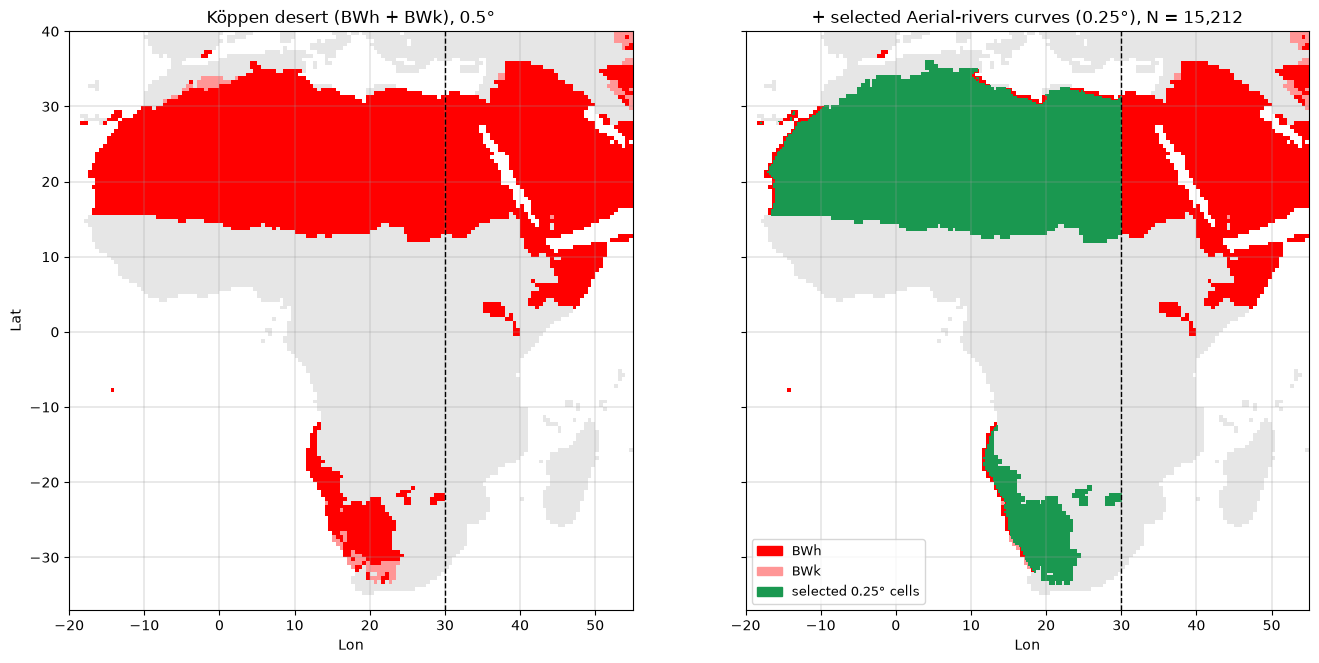

In [103]:
# ---- 1) 非洲：碰到沙漠（BWh + BWk）的 Aerial-rivers 曲線 ----
import xarray as xr

# Aerial-rivers 第 7 節用的 ERA5 曲線（0.25° 陸地格點，只讀座標和 AR6 區域，不讀曲線）
NC = ROOT.parent / "Aerial-rivers" / "data" / "drainage_curves_land.nc"
with xr.open_dataset(NC) as ds:
    c_lat, c_lon = ds.tag_lat.values.astype(float), ds.tag_lon.values.astype(float)
    c_rg = ds.run_group.values.astype(str)

# 非洲 = Reproduce.ipynb 第 7.6 節的 8 個 AR6 區域（含 MDG 馬達加斯加）
#      + MED 區裡在非洲大陸上的格點（AR6 的 MED 包含北非沿岸，撒哈拉北緣的沙漠有一部分在這裡）
AF_RG = ["SAH", "WAF", "CAF", "NEAF", "SEAF", "WSAF", "ESAF", "MDG"]
med_af = (c_rg == "MED") & (c_lon > -18) & (c_lon < 32.6) & (c_lat < 37.4) \
         & ((c_lon < 12) | (c_lat < 34)) & ~((c_lon < -1) & (c_lat > 36))   # 排除西班牙、西西里、馬爾他、克里特、西奈
africa = np.isin(c_rg, AF_RG) | med_af

# 每個 0.25° 格子是 [lat±0.125, lon±0.125]，只要和任何一個 0.5° 沙漠格子重疊就算「削到紅色」
def touches(code_mask, lat, lon, res=0.5, half=0.125, eps=1e-9):
    r0 = np.floor((b.top - (lat + half) + eps) / res).astype(int)    # 格子上緣落在第幾列
    r1 = np.floor((b.top - (lat - half) - eps) / res).astype(int)    # 下緣
    c0 = np.floor((lon - half - b.left + eps) / res).astype(int) % code_mask.shape[1]
    c1 = np.floor((lon + half - b.left - eps) / res).astype(int) % code_mask.shape[1]
    return code_mask[r0, c0] | code_mask[r0, c1] | code_mask[r1, c0] | code_mask[r1, c1]

hit_bwh = touches(g == 4, c_lat, c_lon)
hit_bwk = touches(g == 5, c_lat, c_lon)
AF_EAST = 30.0                                     # 東邊界：只取格點經度 ≤ 30°E
af_desert = africa & (hit_bwh | hit_bwk) & (c_lon <= AF_EAST)
af_idx = np.nonzero(af_desert)[0]                  # nc 的 cell 編號

print(f"Aerial-rivers 曲線總數：{len(c_lat):,}；非洲：{africa.sum():,}（AR6 非洲 8 區 {np.isin(c_rg, AF_RG).sum():,} + MED 北非沿岸 {med_af.sum():,}）")
east = c_lon <= AF_EAST
print(f"非洲、經度 ≤ {AF_EAST:g}°E、碰到沙漠的曲線：{af_desert.sum():,} 條（碰到 BWh {(af_desert & hit_bwh).sum():,}、碰到 BWk {(af_desert & hit_bwk).sum():,}，兩者都碰到 {(af_desert & hit_bwh & hit_bwk).sum():,}）")
print(f"（不設東邊界時是 {(africa & (hit_bwh | hit_bwk)).sum():,} 條）")
for r in AF_RG + ["MED"]:
    n = (af_desert & (c_rg == r)).sum()
    if n: print(f"  {r:>4}: {n:,}")

# 畫圖：左 = read_koppen 的沙漠範圍（紅），右 = 再疊上挑出來的 0.25° 格子（綠）
EXT = (-20, 55, -37, 40)                            # 非洲＋馬達加斯加（west, east, south, north）
# 格點在 0.25° 的整數倍上，第 i 列 = 緯度 EXT[3] − 0.25 i，第 j 欄 = 經度 EXT[0] + 0.25 j
sel = np.full((int((EXT[3] - EXT[2]) / 0.25) + 1, int((EXT[1] - EXT[0]) / 0.25) + 1), np.nan)
sel[np.round((EXT[3] - c_lat[af_idx]) / 0.25).astype(int),
    np.round((c_lon[af_idx] - EXT[0]) / 0.25).astype(int)] = 1
# 每個 0.25° 格子以格點為中心，所以 extent 往外推半格
sel_ext = (EXT[0] - 0.125, EXT[1] + 0.125, EXT[2] - 0.125, EXT[3] + 0.125)

fig, axs = plt.subplots(1, 2, figsize=(16, 8.5), sharey=True)
for ax, overlay in zip(axs, [False, True]):
    ax.imshow(show, cmap=dcm, vmin=-0.5, vmax=3.5, extent=(b.left, b.right, b.bottom, b.top), interpolation="nearest")
    if overlay:
        ax.imshow(sel, cmap=ListedColormap(["#1a9850"]), vmin=0, vmax=1,          # 不透明：沒被綠色蓋住的紅色 = 沒選到的沙漠
                  extent=sel_ext, interpolation="nearest", interpolation_stage="rgba")
    ax.set_xlim(EXT[0], EXT[1]); ax.set_ylim(EXT[2], EXT[3])
    ax.set_xlabel("Lon"); ax.grid(lw=0.3, c="0.6")
    ax.axvline(AF_EAST, c="k", lw=1, ls="--")             # 30°E 東邊界（兩張圖都畫）
axs[0].set_ylabel("Lat")
axs[0].set_title("Köppen desert (BWh + BWk), 0.5°")
axs[1].set_title(f"+ selected Aerial-rivers curves (0.25°), N = {af_desert.sum():,}")
axs[1].legend(handles=[Patch(color=dcm.colors[2], label="BWh"), Patch(color=dcm.colors[3], label="BWk"),
                       Patch(color="#1a9850", label="selected 0.25° cells")], loc="lower left", fontsize=9)
plt.savefig(FIG / "Africa_curves" / "africa_desert_curves_selected.png", dpi=150, bbox_inches="tight")
plt.show()


## 2) 非洲 30°E 上全部格點的排水曲線

第 1 節定義的非洲格點（AR6 非洲 8 區 + MED 北非沿岸）中，取經度剛好在 30°E 那一欄（0.25° 格點）的**全部格點**（不限沙漠），由北到南排好，畫它們的排水曲線。

- 曲線算法和 `Reproduce.ipynb` 第 7.1 節一樣：x = 累積貢獻 C（%），y = 達到 C 所需的上風面積；面積先除以該緯度 1°×1° 的面積（cos 緯度校正，作者式平方度），再在 (C, ln 面積) 上內插成 1000 點。
- 顏色是緯度。

非洲 30°E 上的格點：251 個，緯度 -31.25°～31.25°N；其中碰到沙漠的 79 個
各區： {np.str_('ESAF'): 86, np.str_('MED'): 5, np.str_('NEAF'): 49, np.str_('SAH'): 62, np.str_('SEAF'): 49}


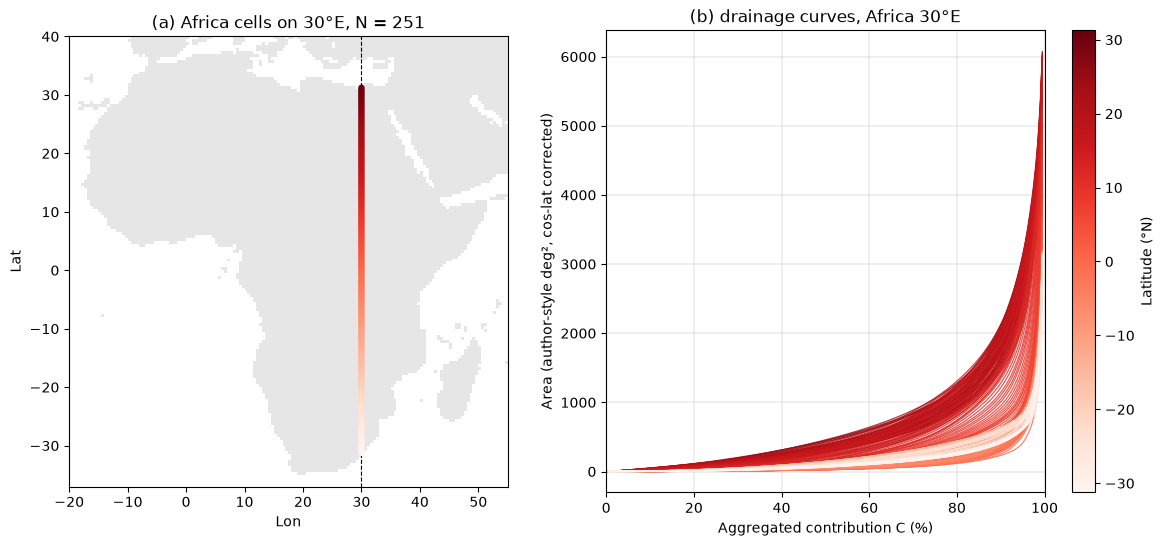

In [104]:
# ---- 2) 非洲 30°E 上全部格點的排水曲線 ----
from matplotlib import cm as mcm
from matplotlib.colors import Normalize

# 第 1 節定義的非洲格點（AR6 非洲 8 區 + MED 北非沿岸）中，經度剛好在 30°E 那一欄的全部格點（不限沙漠）
tr_idx = np.nonzero(africa & np.isclose(c_lon, AF_EAST))[0]
tr_idx = tr_idx[np.argsort(-c_lat[tr_idx])]          # 北 → 南
tr_lat = c_lat[tr_idx]
print(f"非洲 30°E 上的格點：{len(tr_idx)} 個，緯度 {tr_lat.min():.2f}°～{tr_lat.max():.2f}°N；其中碰到沙漠的 {af_desert[tr_idx].sum()} 個")
print("各區：", {r: int((c_rg[tr_idx] == r).sum()) for r in np.unique(c_rg[tr_idx])})

# 曲線：和 Reproduce.ipynb 第 7.1 節同一個算法
#   x = level × 100 = 累積貢獻 C（%），面積 km² ÷ 該緯度 1°×1° 的面積 → 作者式平方度，
#   在 (C, ln(面積 + a)) 上線性內插成 1000 點，a = 最小正面積 ÷ 10
R_E = 6371.0088
def deg2_km2(lat):
    return R_E ** 2 * np.deg2rad(1.0) * (np.sin(np.deg2rad(lat + 0.5)) - np.sin(np.deg2rad(lat - 0.5)))

with xr.open_dataset(NC) as ds:
    x_lv = ds.level.values * 100
    A_km2 = ds.area_at_level.isel(cell=tr_idx).values.astype(float)     # (格點數, 199)
tr_X = np.linspace(x_lv.min(), x_lv.max(), 1000)
y = A_km2 / deg2_km2(tr_lat)[:, None]
a = np.where(y > 0, y, np.inf).min(1, keepdims=True) / 10
tr_A = np.array([np.exp(np.interp(tr_X, x_lv, np.log(yy + aa))) - aa for yy, aa in zip(y, a[:, 0])])

# 畫圖：(a) 格點位置 (b) 曲線，顏色 = 緯度
nrm = Normalize(tr_lat.min(), tr_lat.max()); cmp = mcm.Reds
fig, axs = plt.subplots(1, 2, figsize=(14, 6), gridspec_kw={"width_ratios": [0.8, 1]})
ax = axs[0]
ax.imshow(np.where(g > 0, 1, 0), cmap=dcm, vmin=-0.5, vmax=3.5,       # 只畫陸地（灰），不畫沙漠
          extent=(b.left, b.right, b.bottom, b.top), interpolation="nearest")
ax.axvline(AF_EAST, c="k", lw=0.8, ls="--")
ax.scatter(c_lon[tr_idx], tr_lat, c=tr_lat, cmap=cmp, norm=nrm, s=12, zorder=3)
ax.set_xlim(EXT[0], EXT[1]); ax.set_ylim(EXT[2], EXT[3]); ax.set_xlabel("Lon"); ax.set_ylabel("Lat")
ax.set_title(f"(a) Africa cells on 30°E, N = {len(tr_idx)}")
ax = axs[1]
for yy, la in zip(tr_A, tr_lat):
    ax.plot(tr_X, yy, c=cmp(nrm(la)), lw=0.9, alpha=0.8)
ax.set_xlim(0, 100); ax.set_xlabel("Aggregated contribution C (%)")
ax.set_ylabel("Area (author-style deg², cos-lat corrected)")
ax.grid(lw=0.3, c="0.7"); ax.set_title("(b) drainage curves, Africa 30°E")
fig.colorbar(mcm.ScalarMappable(nrm, cmp), ax=ax, label="Latitude (°N)")
plt.savefig(FIG / "Africa_curves" / "africa_30E_curves.png", dpi=150, bbox_inches="tight")
plt.show()


## 3) 20°N 由東往西的曲線演變（仿 Weng et al. Fig. S4）

沿 20°N，從 20°E 每隔 5° 往西取到 10°W（東北信風的方向，由上游往下游），畫出各點的排水曲線。做法照論文補充圖 Fig. S4：

- **(a)** 各點的曲線，x 只看 C = 50–100%（曲線差異主要在後段），顏色由淺紅（起點 20°E）到深紅（終點 10°W），底圖只畫陸地。
- **(b)** 各點位置，箭頭是取點順序。
- **(c)** 起點和終點兩條曲線的完整 0–100%，用來看曲線形狀「怎麼變」：是轉折點往左移（橫向），還是曲線整條往上抬（縱向）。
- 最後列出每個點的轉折點（Reproduce 第 6 節的作者算法）和 C = 50 / 80 / 90% 需要的面積。

曲線算法和第 2 節相同（Reproduce 7.1：cos 緯度校正的作者式平方度）。`STEP` 改成 1.5 就和論文的格距一樣。

7 個點：20°E、15°E、10°E、5°E、0°E、-5°E、-10°E；區域 [np.str_('SAH')]；全部在沙漠裡：True


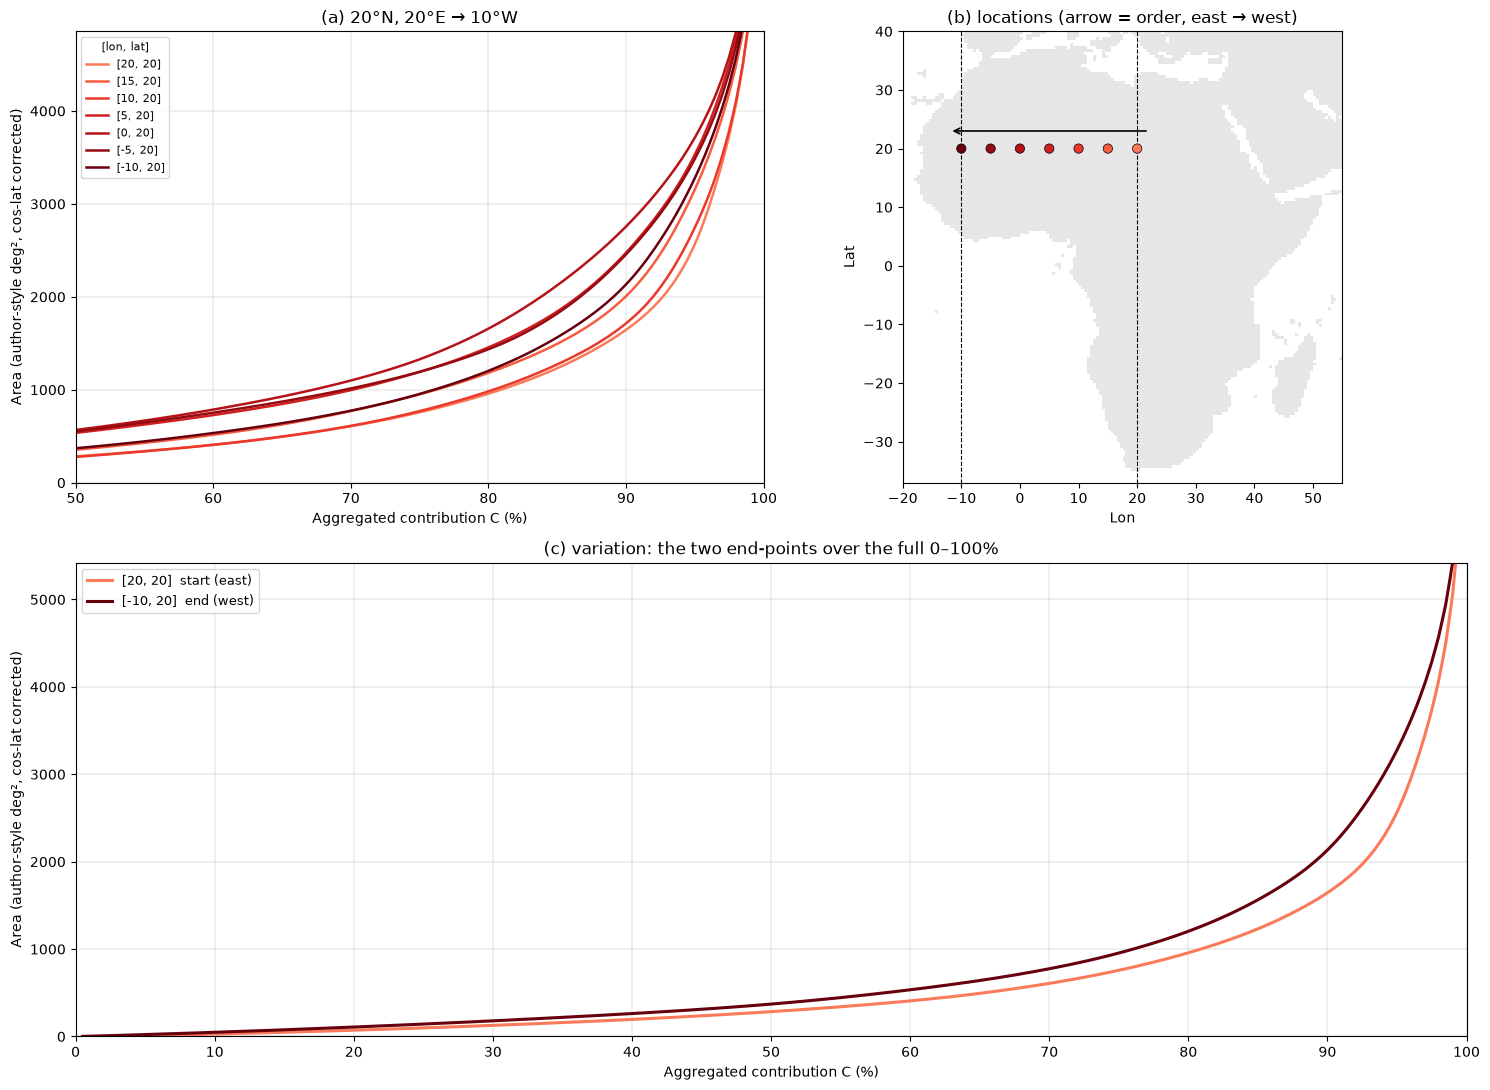

             點     轉折點 C(%)      A50      A80      A90
      [20, 20]         62.9      284      958     1644
      [15, 20]          4.0      354     1182     2006
      [10, 20]         42.8      277      983     1714
       [5, 20]         67.4      536     1456     2474
       [0, 20]         73.4      567     1658     2756
      [-5, 20]         81.0      552     1436     2456
     [-10, 20]         48.8      371     1204     2133


In [105]:
# ---- 3) 20°N 由東往西（20°E → 10°W）的排水曲線演變（仿 Weng et al. Fig. S4）----
TR_LAT, LON_E, LON_W, STEP = 20.0, 20.0, -10.0, 5.0     # STEP：每隔幾度取一點（改這裡就能加密）
want = np.arange(LON_E, LON_W - 1e-9, -STEP)               # 20, 15, ..., −10（東 → 西，順著東北信風往下游）
s10_idx = []
for lo in want:
    k = np.nonzero(np.isclose(c_lat, TR_LAT) & np.isclose(c_lon, lo))[0]
    if len(k): s10_idx.append(k[0])
    else: print(f"  ({lo:g}, {TR_LAT:g}) 沒有格點，跳過")
s10_idx = np.array(s10_idx)
s10_lon, s10_lat = c_lon[s10_idx], c_lat[s10_idx]
print(f"{len(s10_idx)} 個點：" + "、".join(f"{lo:g}°E" for lo in s10_lon)
      + f"；區域 {sorted(set(c_rg[s10_idx]))}；全部在沙漠裡：{af_desert[s10_idx].all()}")

# 曲線：和第 2 節同一個算法（Reproduce 7.1：cos 緯度校正的作者式平方度，ln 面積內插 1000 點）
def curves_for(idx):
    with xr.open_dataset(NC) as ds:
        A = ds.area_at_level.isel(cell=idx).values.astype(float)
    y = A / deg2_km2(c_lat[idx])[:, None]
    a = np.where(y > 0, y, np.inf).min(1) / 10
    return np.array([np.exp(np.interp(tr_X, x_lv, np.log(yy + aa))) - aa for yy, aa in zip(y, a)])
s10_A = curves_for(s10_idx)

# 顏色：起點（20°E）淺紅 → 終點（10°W）深紅，和 Fig. S4 一樣（底圖只畫陸地，不畫沙漠）
s10_col = plt.cm.Reds(np.linspace(0.45, 1.0, len(s10_idx)))
lab = [f"[{lo:g}, {la:g}]" for lo, la in zip(s10_lon, s10_lat)]

fig = plt.figure(figsize=(15, 11))
gs = fig.add_gridspec(2, 2, height_ratios=[1, 1.05])
# (a) 曲線，x 只看 50–100%（和 Fig. S4a 一樣）
ax = fig.add_subplot(gs[0, 0])
for yy, c, l in zip(s10_A, s10_col, lab):
    ax.plot(tr_X, yy, c=c, lw=1.8, label=l)
ax.set_xlim(50, 100); ax.set_ylim(0, np.interp(98, tr_X, s10_A.max(0)))
ax.set_xlabel("Aggregated contribution C (%)"); ax.set_ylabel("Area (author-style deg², cos-lat corrected)")
ax.grid(lw=0.3, c="0.7"); ax.legend(fontsize=8, title="[lon, lat]", title_fontsize=8)
ax.set_title(f"(a) {TR_LAT:g}°N, {LON_E:g}°E → {abs(LON_W):g}°W")
# (b) 點的位置
ax = fig.add_subplot(gs[0, 1])
ax.imshow(np.where(g > 0, 1, 0), cmap=dcm, vmin=-0.5, vmax=3.5,       # 只畫陸地（灰），不畫沙漠
          extent=(b.left, b.right, b.bottom, b.top), interpolation="nearest")
for lo in (LON_E, LON_W):                                   # 剖面的東、西端經線（20°E、10°W）
    ax.axvline(lo, c="k", lw=0.8, ls="--")
ax.scatter(s10_lon, s10_lat, c=s10_col, s=45, edgecolors="k", linewidths=0.5, zorder=3)
ax.annotate("", xy=(s10_lon[-1] - 2, TR_LAT + 3), xytext=(s10_lon[0] + 2, TR_LAT + 3),
            arrowprops=dict(arrowstyle="->", lw=1.2))
ax.set_xlim(EXT[0], EXT[1]); ax.set_ylim(EXT[2], EXT[3]); ax.set_xlabel("Lon"); ax.set_ylabel("Lat")
ax.set_title("(b) locations (arrow = order, east → west)")
# (c) 兩個端點的完整曲線（0–100%），看「形狀怎麼變」
ax = fig.add_subplot(gs[1, :])
for i, ls in [(0, "-"), (len(s10_idx) - 1, "-")]:
    ax.plot(tr_X, s10_A[i], c=s10_col[i], lw=2.2, ls=ls, label=f"{lab[i]}  {'start (east)' if i == 0 else 'end (west)'}")
ax.set_xlim(0, 100); ax.set_ylim(0, np.interp(99, tr_X, s10_A[[0, -1]].max(0)))
ax.set_xticks(range(0, 101, 10))
ax.set_xlabel("Aggregated contribution C (%)"); ax.set_ylabel("Area (author-style deg², cos-lat corrected)")
ax.grid(lw=0.3, c="0.7"); ax.legend(fontsize=9)
ax.set_title("(c) variation: the two end-points over the full 0–100%")
plt.tight_layout()
plt.savefig(FIG / "Africa_curves" / "africa_20N_E2W_curves.png", dpi=150, bbox_inches="tight")
plt.show()

# 轉折點（Reproduce 第 6 節的作者算法）與 A50，用來看是「往左移」還是「往上移」
from scipy.ndimage import gaussian_filter1d
from scipy.signal import medfilt, find_peaks
def turning(x, y):
    s = np.empty(len(x))
    s[0] = (y[1] - y[0]) / (x[1] - x[0]); s[1] = (y[2] - y[0]) / (x[2] - x[0])
    s[-2] = (y[-1] - y[-3]) / (x[-1] - x[-3]); s[-1] = (y[-1] - y[-2]) / (x[-1] - x[-2])
    s[2:-2] = (y[4:] - y[:-4]) / (x[4:] - x[:-4])
    th = np.degrees(np.arctan(s / 10))                       # y ÷ 10，和作者一樣
    d = gaussian_filter1d(medfilt(np.gradient(th), 15), 10)
    p, _ = find_peaks(d, prominence=0.05)
    return x[p[0]] if len(p) else np.nan
print(f"{'點':>14} {'轉折點 C(%)':>12} {'A50':>8} {'A80':>8} {'A90':>8}")
for l, yy in zip(lab, s10_A):
    print(f"{l:>14} {turning(tr_X, yy):12.1f} " + " ".join(f"{np.interp(q, tr_X, yy):8.0f}" for q in (50, 80, 90)))


20°N 上、地圖範圍內的陸地格點：213 個，經度 -16～37；區域 {np.str_('SAH'): 213}
阿拉伯半島（ARP）格點：59 個，經度 40.5～55


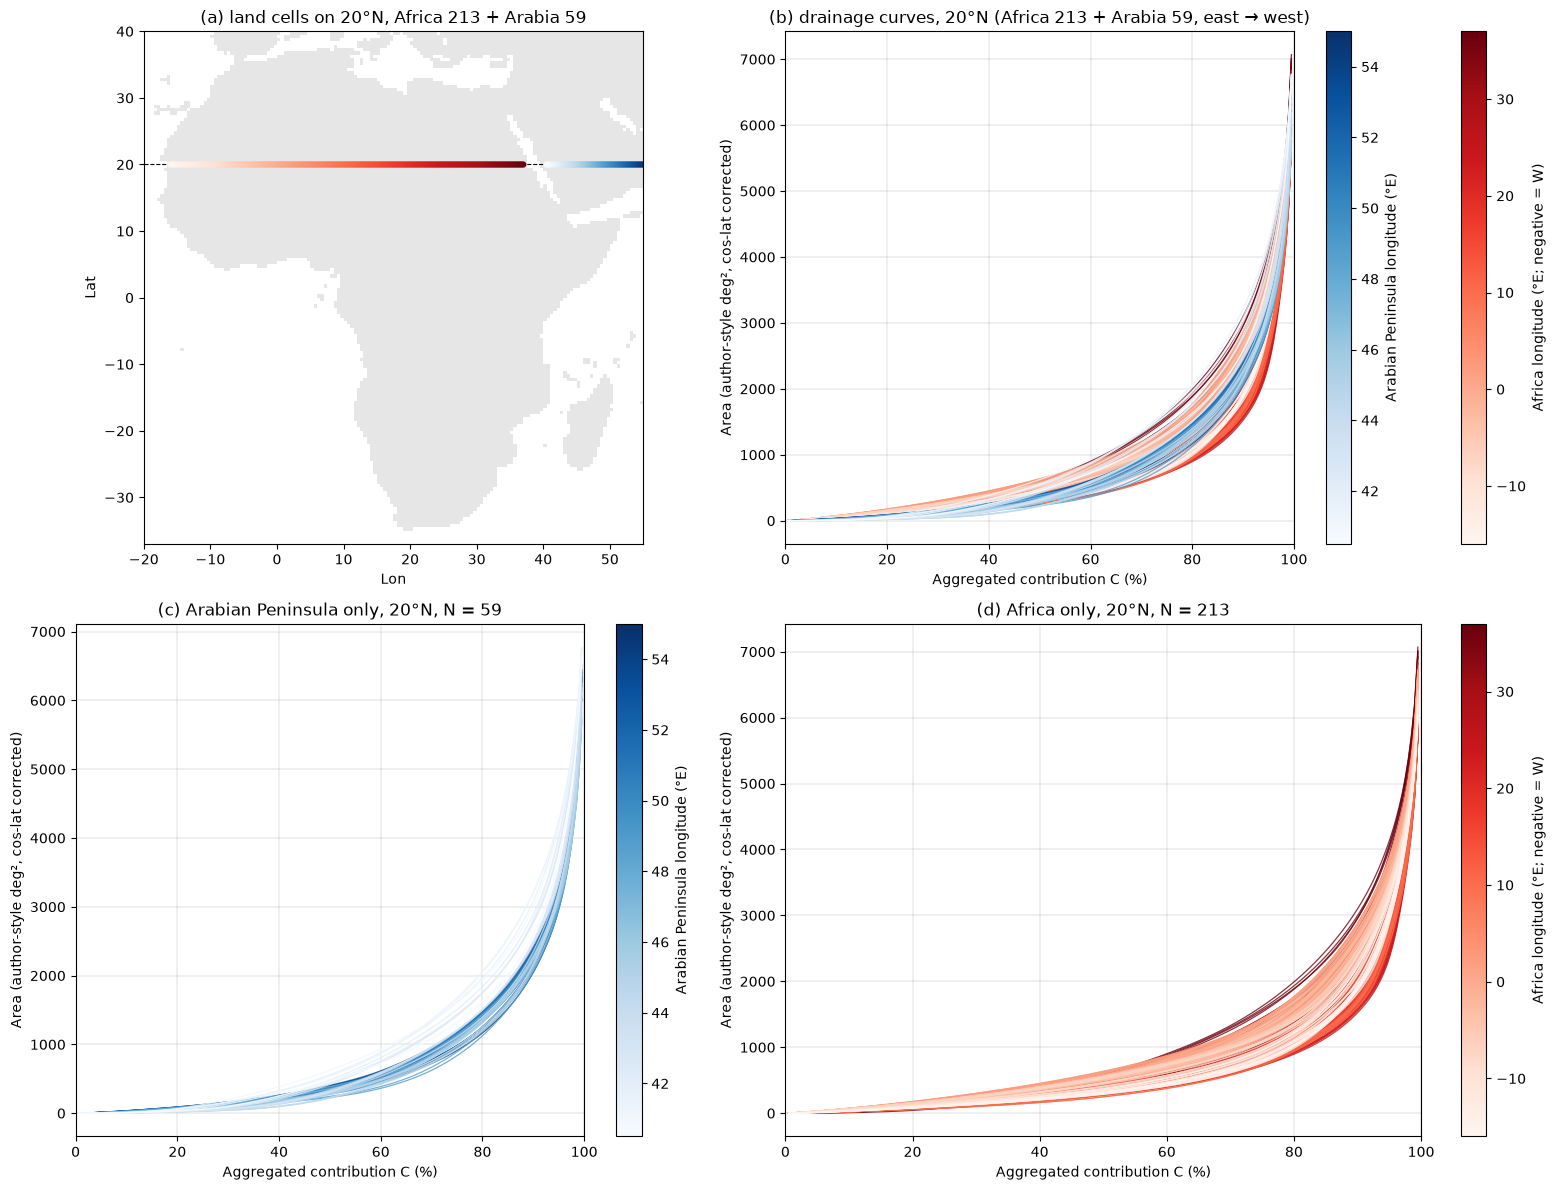

In [106]:
# ---- 3b) 第 3 節的連續格點版本（仿第 2 節）：固定緯線上、(b) 地圖範圍內的全部陸地格點 ----
# 用第 3 節的 TR_LAT 和 EXT，取這條線上每 0.25° 的全部陸地格點（不限兩端、不限沙漠；海上沒有格點，自然留空）
s3c_idx = np.nonzero(np.isclose(c_lat, TR_LAT) & (c_lon >= EXT[0]) & (c_lon <= EXT[1]))[0]
# 篩選：只留非洲，去掉同一條緯線上的阿拉伯半島（AR6 ARP）
s3c_all = s3c_idx                                                  # 篩選前（含阿拉伯半島）
s3c_idx = s3c_idx[c_rg[s3c_idx] != "ARP"]
# 阿拉伯半島另外畫（Blues）：同一條緯線上 AR6 ARP 的格點，東 → 西
s3c_ar_idx = s3c_all[c_rg[s3c_all] == "ARP"]
s3c_ar_idx = s3c_ar_idx[np.argsort(-c_lon[s3c_ar_idx])]
s3c_ar_v = c_lon[s3c_ar_idx]
s3c_idx = s3c_idx[np.argsort(-c_lon[s3c_idx])]                       # 東 → 西
s3c_v = c_lon[s3c_idx]                                              # 上色用的經度
print(f"{abs(TR_LAT):g}°{'N' if TR_LAT >= 0 else 'S'} 上、地圖範圍內的陸地格點：{len(s3c_idx)} 個，經度 {s3c_v.min():g}～{s3c_v.max():g}；"
      f"區域 { {r: int((c_rg[s3c_idx] == r).sum()) for r in np.unique(c_rg[s3c_idx])} }")

s3c_A = curves_for(s3c_idx)                                          # 第 3 節定義的函式（和第 2 節同一個算法）
s3c_ar_A = curves_for(s3c_ar_idx)                                    # 阿拉伯半島的曲線
print(f"阿拉伯半島（ARP）格點：{len(s3c_ar_idx)} 個，經度 {s3c_ar_v.min():g}～{s3c_ar_v.max():g}")

# 顏色：Reds_r，經度/緯度數值越大越淺、越小越深
s3c_nrm = Normalize(s3c_v.min(), s3c_v.max()); s3c_cmp = plt.cm.Reds
s3c_ar_nrm = Normalize(s3c_ar_v.min(), s3c_ar_v.max()); s3c_ar_cmp = plt.cm.Blues   # 阿拉伯半島用 Blues
# 2×2：上排 = 原本的地圖＋全部曲線；下排左 = 只畫阿拉伯半島（藍），下排右 = 只畫非洲（紅）
fig, axs = plt.subplots(2, 2, figsize=(16, 12), gridspec_kw={"width_ratios": [0.8, 1]})
s3c_lat_txt = f"{abs(TR_LAT):g}°{'N' if TR_LAT >= 0 else 'S'}"
def s3c_curves(ax, A, v, cmp, nrm):                                # 畫一組曲線（和第 2 節同樣的格式）
    for yy, vv in zip(A, v):
        ax.plot(tr_X, yy, c=cmp(nrm(vv)), lw=0.9, alpha=0.8)
    ax.set_xlim(0, 100); ax.set_xlabel("Aggregated contribution C (%)")
    ax.set_ylabel("Area (author-style deg², cos-lat corrected)"); ax.grid(lw=0.3, c="0.7")
# 左上：地圖
ax = axs[0, 0]
ax.imshow(np.where(g > 0, 1, 0), cmap=dcm, vmin=-0.5, vmax=3.5,       # 只畫陸地（灰）
          extent=(b.left, b.right, b.bottom, b.top), interpolation="nearest")
ax.axhline(TR_LAT, c="k", lw=0.8, ls="--")                              # 固定的緯線
ax.scatter(c_lon[s3c_idx], c_lat[s3c_idx], c=s3c_v, cmap=s3c_cmp, norm=s3c_nrm, s=12, zorder=3)
ax.scatter(c_lon[s3c_ar_idx], c_lat[s3c_ar_idx], c=s3c_ar_v, cmap=s3c_ar_cmp, norm=s3c_ar_nrm, s=12, zorder=3)
ax.set_xlim(EXT[0], EXT[1]); ax.set_ylim(EXT[2], EXT[3]); ax.set_xlabel("Lon"); ax.set_ylabel("Lat")
ax.set_title(f"(a) land cells on {s3c_lat_txt}, Africa {len(s3c_idx)} + Arabia {len(s3c_ar_idx)}")
# 右上：全部曲線（紅＋藍）
ax = axs[0, 1]
s3c_curves(ax, s3c_A, s3c_v, s3c_cmp, s3c_nrm)
s3c_curves(ax, s3c_ar_A, s3c_ar_v, s3c_ar_cmp, s3c_ar_nrm)
ax.set_title(f"(b) drainage curves, {s3c_lat_txt} (Africa {len(s3c_idx)} + Arabia {len(s3c_ar_idx)}, east → west)")
fig.colorbar(mcm.ScalarMappable(s3c_nrm, s3c_cmp), ax=ax, label="Africa longitude (°E; negative = W)")
fig.colorbar(mcm.ScalarMappable(s3c_ar_nrm, s3c_ar_cmp), ax=ax, label="Arabian Peninsula longitude (°E)")
# 左下：只畫阿拉伯半島（藍）
ax = axs[1, 0]
s3c_curves(ax, s3c_ar_A, s3c_ar_v, s3c_ar_cmp, s3c_ar_nrm)
ax.set_title(f"(c) Arabian Peninsula only, {s3c_lat_txt}, N = {len(s3c_ar_idx)}")
fig.colorbar(mcm.ScalarMappable(s3c_ar_nrm, s3c_ar_cmp), ax=ax, label="Arabian Peninsula longitude (°E)")
# 右下：只畫非洲（紅）
ax = axs[1, 1]
s3c_curves(ax, s3c_A, s3c_v, s3c_cmp, s3c_nrm)
ax.set_title(f"(d) Africa only, {s3c_lat_txt}, N = {len(s3c_idx)}")
fig.colorbar(mcm.ScalarMappable(s3c_nrm, s3c_cmp), ax=ax, label="Africa longitude (°E; negative = W)")
plt.tight_layout()
plt.savefig(FIG / "Africa_curves" / f"africa_{TR_LAT:g}N_E2W_curves_continuous.png", dpi=150, bbox_inches="tight")
plt.show()

## 4) 南美洲 5°S 由東往西的曲線演變（同第 3 節做法）

沿 5°S，從 35°W 每隔 5° 往西取到 80°W（東南信風把大西洋水氣往西送進亞馬遜，由上游往下游），畫法和第 3 節一模一樣：

- **(a)** 各點的曲線，x 只看 C = 50–100%，顏色由淺紅（起點 35°W）到深紅（終點 80°W）。
- **(b)** 各點位置（南美洲，底圖只畫陸地），虛線是東西兩端的經線，箭頭是取點順序。
- **(c)** 起點和終點兩條曲線的完整 0–100%。
- 最後列出每個點的 AR6 區域、是否碰到 Köppen 沙漠（BWh/BWk）、轉折點與 C = 50 / 80 / 90% 需要的面積。

nc 裡沒有格點的經度（例如已經在海上）會印出並跳過。重用第 3 節的 `curves_for`、`turning`，變數用 `s4_` 開頭，不會蓋掉第 3 節的 `s10_`。圖存在 `../Figure/SA_curves/`。

6 個點：39°W(NES)、40.5°W(NES)、42°W(NES)、43.5°W(NES)、45°W(NES)、46.5°W(NES)
區域 [np.str_('NES')]；碰到沙漠的點：無


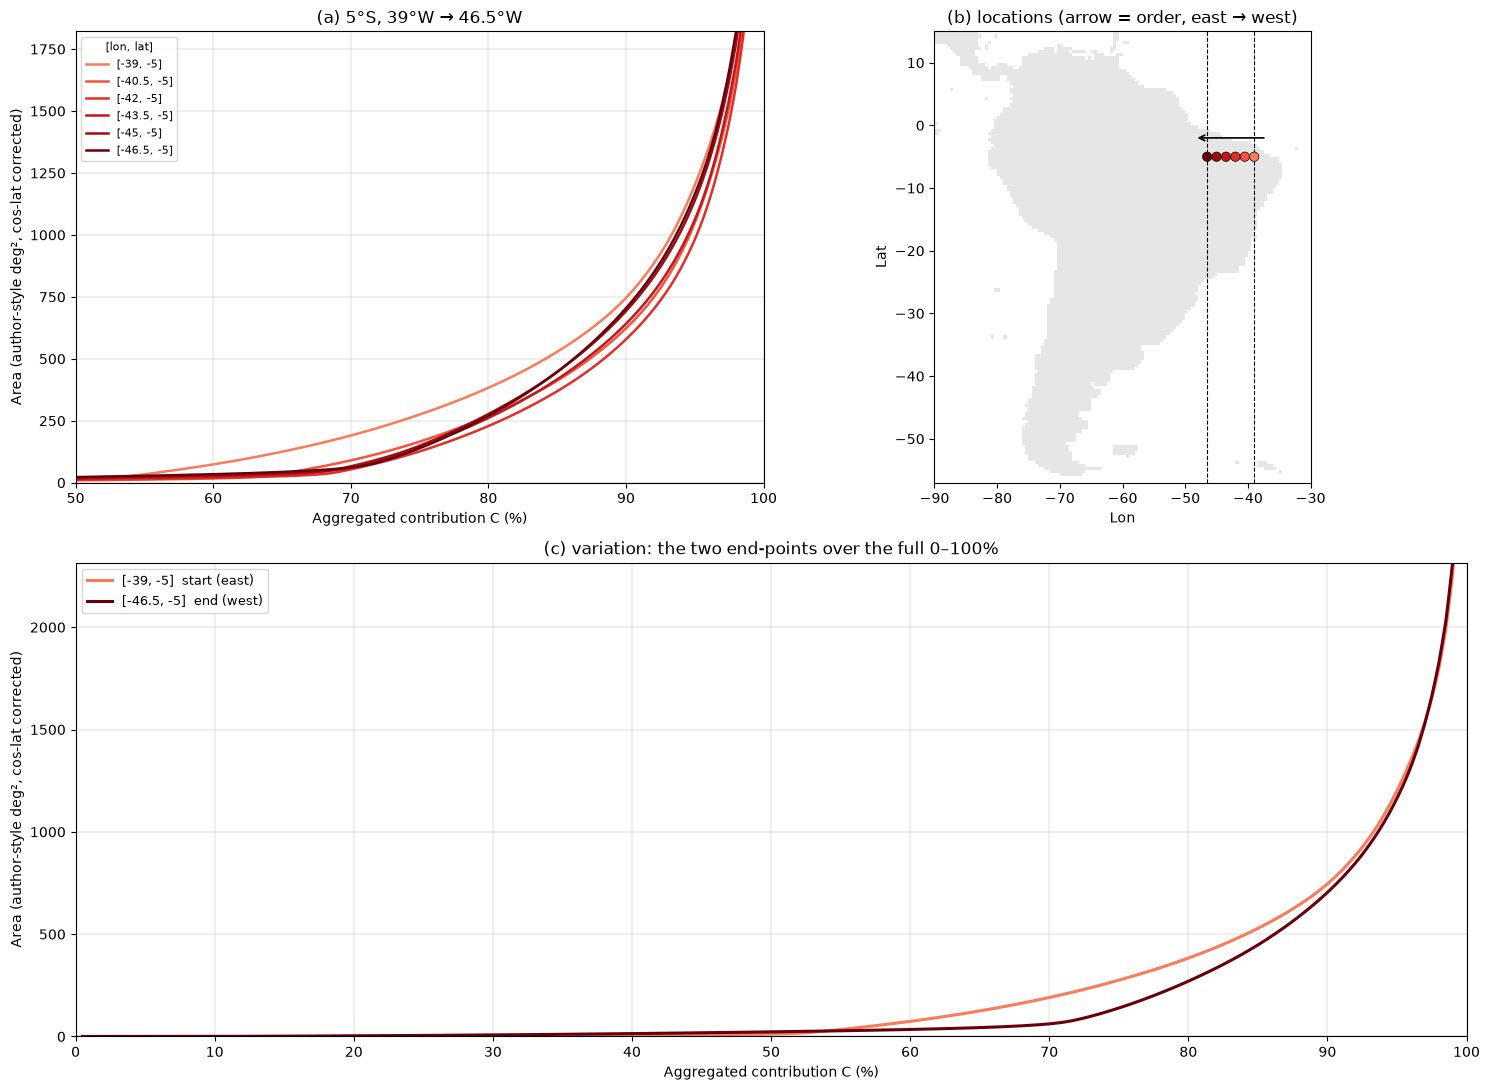

             點    區域   沙漠     轉折點 C(%)      A50      A80      A90
     [-39, -5]   NES    否         52.1       12      383      746
   [-40.5, -5]   NES    否         63.5       10      270      623
     [-42, -5]   NES    否         68.2       12      229      579
   [-43.5, -5]   NES    否         67.8       16      261      641
     [-45, -5]   NES    否         69.4       20      277      692
   [-46.5, -5]   NES    否         70.8       23      270      704


In [107]:
# ---- 4) 南美洲 5°S 由東往西（35°W → 80°W）的排水曲線演變（同第 3 節）----
# 需要先跑過 setup、第 1 節（c_lat/c_lon/c_rg、hit_bwh/hit_bwk）、第 2 節（deg2_km2、x_lv、tr_X）、第 3 節（curves_for、turning）
(FIG / "SA_curves").mkdir(parents=True, exist_ok=True)
s4_LAT, s4_LON_E, s4_LON_W, s4_STEP = -5.0, -39.0, -46.5, 1.5    # STEP：每隔幾度取一點
s4_want = np.arange(s4_LON_E, s4_LON_W - 1e-9, -s4_STEP)         # −35, −40, ..., −80（東 → 西）
s4_idx = []
for lo in s4_want:
    k = np.nonzero(np.isclose(c_lat, s4_LAT) & np.isclose(c_lon, lo))[0]
    if len(k): s4_idx.append(k[0])
    else: print(f"  ({lo:g}, {s4_LAT:g}) 沒有格點，跳過")
s4_idx = np.array(s4_idx)
s4_lon, s4_lat = c_lon[s4_idx], c_lat[s4_idx]
s4_desert = (hit_bwh | hit_bwk)[s4_idx]                           # 是否碰到 Köppen 沙漠（BWh + BWk）
print(f"{len(s4_idx)} 個點：" + "、".join(f"{abs(lo):g}°W({r})" for lo, r in zip(s4_lon, c_rg[s4_idx])))
print(f"區域 {sorted(set(c_rg[s4_idx]))}；碰到沙漠的點：{[f'{abs(lo):g}°W' for lo in s4_lon[s4_desert]] or '無'}")

s4_A = curves_for(s4_idx)                                          # 第 3 節定義的函式

# 顏色：起點（35°W）淺紅 → 終點（80°W）深紅
s4_col = plt.cm.Reds(np.linspace(0.45, 1.0, len(s4_idx)))
s4_lab = [f"[{lo:g}, {la:g}]" for lo, la in zip(s4_lon, s4_lat)]
s4_EXT = (-90, -30, -57, 15)                                       # 南美洲（west, east, south, north）

fig = plt.figure(figsize=(15, 11))
gs = fig.add_gridspec(2, 2, height_ratios=[1, 1.05])
# (a) 曲線，x 只看 50–100%
ax = fig.add_subplot(gs[0, 0])
for yy, c, l in zip(s4_A, s4_col, s4_lab):
    ax.plot(tr_X, yy, c=c, lw=1.8, label=l)
ax.set_xlim(50, 100); ax.set_ylim(0, np.interp(98, tr_X, s4_A.max(0)))
ax.set_xlabel("Aggregated contribution C (%)"); ax.set_ylabel("Area (author-style deg², cos-lat corrected)")
ax.grid(lw=0.3, c="0.7"); ax.legend(fontsize=8, title="[lon, lat]", title_fontsize=8)
ax.set_title(f"(a) {abs(s4_LAT):g}°S, {abs(s4_LON_E):g}°W → {abs(s4_LON_W):g}°W")
# (b) 點的位置
ax = fig.add_subplot(gs[0, 1])
ax.imshow(np.where(g > 0, 1, 0), cmap=dcm, vmin=-0.5, vmax=3.5,       # 只畫陸地（灰），不畫沙漠
          extent=(b.left, b.right, b.bottom, b.top), interpolation="nearest")
for lo in (s4_LON_E, s4_LON_W):                                   # 剖面的東、西端經線（35°W、80°W）
    ax.axvline(lo, c="k", lw=0.8, ls="--")
ax.scatter(s4_lon, s4_lat, c=s4_col, s=45, edgecolors="k", linewidths=0.5, zorder=3)
ax.annotate("", xy=(s4_lon[-1] - 2, s4_LAT + 3), xytext=(s4_lon[0] + 2, s4_LAT + 3),
            arrowprops=dict(arrowstyle="->", lw=1.2))
ax.set_xlim(s4_EXT[0], s4_EXT[1]); ax.set_ylim(s4_EXT[2], s4_EXT[3]); ax.set_xlabel("Lon"); ax.set_ylabel("Lat")
ax.set_title("(b) locations (arrow = order, east → west)")
# (c) 兩個端點的完整曲線（0–100%）
ax = fig.add_subplot(gs[1, :])
for i in (0, len(s4_idx) - 1):
    ax.plot(tr_X, s4_A[i], c=s4_col[i], lw=2.2, label=f"{s4_lab[i]}  {'start (east)' if i == 0 else 'end (west)'}")
ax.set_xlim(0, 100); ax.set_ylim(0, np.interp(99, tr_X, s4_A[[0, -1]].max(0)))
ax.set_xticks(range(0, 101, 10))
ax.set_xlabel("Aggregated contribution C (%)"); ax.set_ylabel("Area (author-style deg², cos-lat corrected)")
ax.grid(lw=0.3, c="0.7"); ax.legend(fontsize=9)
ax.set_title("(c) variation: the two end-points over the full 0–100%")
plt.tight_layout()
plt.savefig(FIG / "SA_curves" / "sa_5S_E2W_curves.png", dpi=150, bbox_inches="tight")
plt.show()

# 轉折點（第 3 節的 turning）與 A50 / A80 / A90
print(f"{'點':>14} {'區域':>5} {'沙漠':>4} {'轉折點 C(%)':>12} {'A50':>8} {'A80':>8} {'A90':>8}")
for l, r, d, yy in zip(s4_lab, c_rg[s4_idx], s4_desert, s4_A):
    print(f"{l:>14} {r:>5} {'是' if d else '否':>4} {turning(tr_X, yy):12.1f} "
          + " ".join(f"{np.interp(q, tr_X, yy):8.0f}" for q in (50, 80, 90)))

5°S 上、地圖範圍內的陸地格點：177 個，經度 -81～-37；區域 {np.str_('NES'): 52, np.str_('NSA'): 88, np.str_('NWS'): 37}


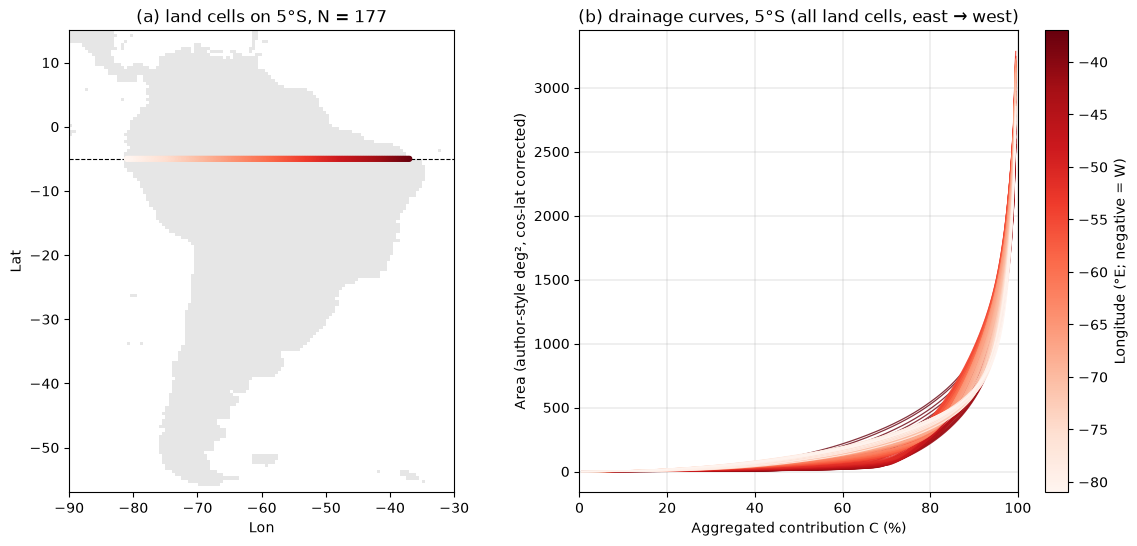

In [108]:
# ---- 4b) 第 4 節的連續格點版本（仿第 2 節）：固定緯線上、(b) 地圖範圍內的全部陸地格點 ----
# 用第 4 節的 s4_LAT 和 s4_EXT，取這條線上每 0.25° 的全部陸地格點（不限兩端、不限沙漠；海上沒有格點，自然留空）
s4c_idx = np.nonzero(np.isclose(c_lat, s4_LAT) & (c_lon >= s4_EXT[0]) & (c_lon <= s4_EXT[1]))[0]
s4c_idx = s4c_idx[np.argsort(-c_lon[s4c_idx])]                       # 東 → 西
s4c_v = c_lon[s4c_idx]                                              # 上色用的經度
print(f"{abs(s4_LAT):g}°{'N' if s4_LAT >= 0 else 'S'} 上、地圖範圍內的陸地格點：{len(s4c_idx)} 個，經度 {s4c_v.min():g}～{s4c_v.max():g}；"
      f"區域 { {r: int((c_rg[s4c_idx] == r).sum()) for r in np.unique(c_rg[s4c_idx])} }")

s4c_A = curves_for(s4c_idx)                                          # 第 3 節定義的函式（和第 2 節同一個算法）

# 顏色：Reds_r，經度/緯度數值越大越淺、越小越深
s4c_nrm = Normalize(s4c_v.min(), s4c_v.max()); s4c_cmp = plt.cm.Reds
fig, axs = plt.subplots(1, 2, figsize=(14, 6), gridspec_kw={"width_ratios": [0.8, 1]})
ax = axs[0]
ax.imshow(np.where(g > 0, 1, 0), cmap=dcm, vmin=-0.5, vmax=3.5,       # 只畫陸地（灰）
          extent=(b.left, b.right, b.bottom, b.top), interpolation="nearest")
ax.axhline(s4_LAT, c="k", lw=0.8, ls="--")                              # 固定的緯線
ax.scatter(c_lon[s4c_idx], c_lat[s4c_idx], c=s4c_v, cmap=s4c_cmp, norm=s4c_nrm, s=12, zorder=3)
ax.set_xlim(s4_EXT[0], s4_EXT[1]); ax.set_ylim(s4_EXT[2], s4_EXT[3]); ax.set_xlabel("Lon"); ax.set_ylabel("Lat")
ax.set_title(f"(a) land cells on {abs(s4_LAT):g}°{'N' if s4_LAT >= 0 else 'S'}, N = {len(s4c_idx)}")
ax = axs[1]
for yy, v in zip(s4c_A, s4c_v):
    ax.plot(tr_X, yy, c=s4c_cmp(s4c_nrm(v)), lw=0.9, alpha=0.8)
ax.set_xlim(0, 100); ax.set_xlabel("Aggregated contribution C (%)")
ax.set_ylabel("Area (author-style deg², cos-lat corrected)")
ax.grid(lw=0.3, c="0.7"); ax.set_title(f"(b) drainage curves, {abs(s4_LAT):g}°{'N' if s4_LAT >= 0 else 'S'} (all land cells, east → west)")
fig.colorbar(mcm.ScalarMappable(s4c_nrm, s4c_cmp), ax=ax, label="Longitude (°E; negative = W)")
plt.savefig(FIG / "SA_curves" / f"sa_{abs(s4_LAT):g}S_E2W_curves_continuous.png", dpi=150, bbox_inches="tight")
plt.show()

## 5) 南美南部 40°S 由東往西的曲線演變（同第 4 節做法）

沿 40°S，從 65°W 每隔 2° 往西取到 75°W（範圍只有 10°，用 5° 只有 3 點，所以先用 2°，改 `s5_STEP` 就能調），畫法和第 4 節一模一樣：

- ⚠️ **風向提醒**：40°S 在西風帶，盛行風是由西往東吹，所以這裡「東 → 西」是**逆著盛行風**（從下游往上游），和第 3 節（20°N 東北信風）、第 4 節（5°S 東南信風）順著風走的方向相反，解讀曲線演變時要反過來看。
- **(a)** 各點的曲線，x 只看 C = 50–100%，顏色由淺紅（起點 65°W）到深紅（終點 75°W）。
- **(b)** 各點位置（南美南部，底圖只畫陸地），虛線是東西兩端的經線，箭頭是取點順序。
- **(c)** 起點和終點兩條曲線的完整 0–100%。
- 最後列出每個點的 AR6 區域、是否碰到 Köppen 沙漠（BWh/BWk）、轉折點與 C = 50 / 80 / 90% 需要的面積。

nc 裡沒有格點的經度（75°W 已在太平洋上）會印出並跳過。重用第 3 節的 `curves_for`、`turning`，變數用 `s5_` 開頭，不會蓋掉 `s4_`、`s10_`。圖存在 `../Figure/SA_curves/`。

  (-74, -40) 沒有格點，跳過
6 個點：65°W(SSA)、66.5°W(SSA)、68°W(SSA)、69.5°W(SSA)、71°W(SWS)、72.5°W(SWS)
區域 [np.str_('SSA'), np.str_('SWS')]；碰到沙漠的點：['68°W', '69.5°W']


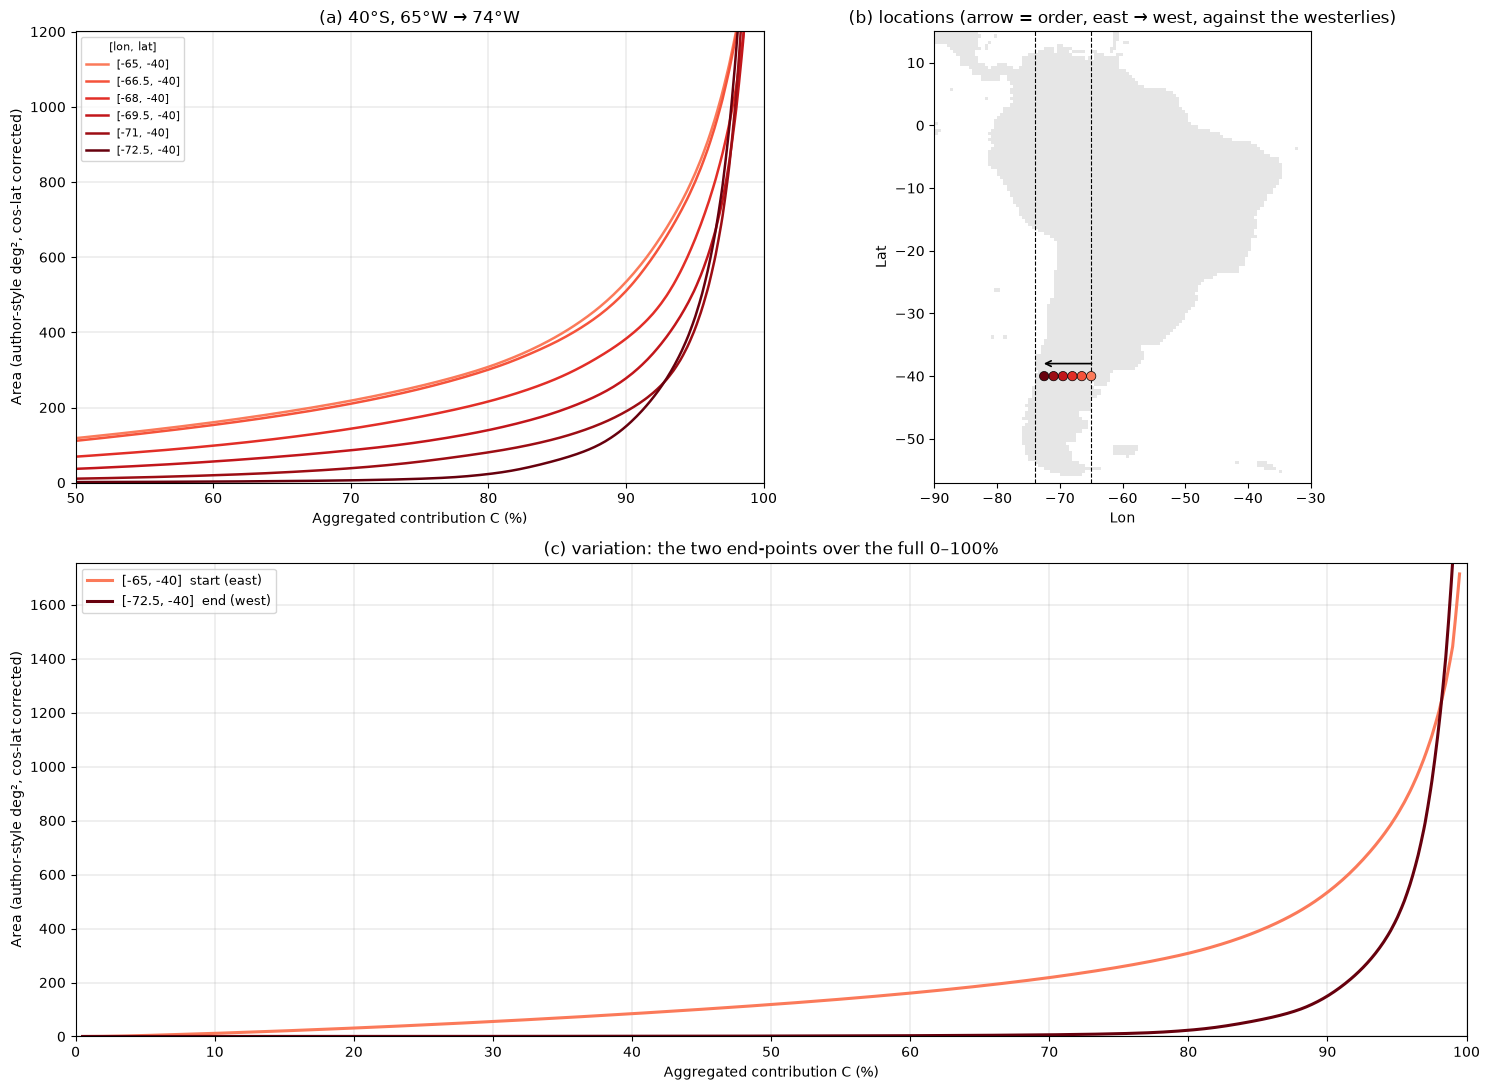

             點    區域   沙漠     轉折點 C(%)      A50      A80      A90
    [-65, -40]   SSA    否         80.6      119      308      534
  [-66.5, -40]   SSA    否         88.0      111      301      510
    [-68, -40]   SSA    是         84.9       69      216      383
  [-69.5, -40]   SSA    是         88.9       37      140      278
    [-71, -40]   SWS    否         73.8       11       81      190
  [-72.5, -40]   SWS    否         81.3        2       23      150


In [109]:
# ---- 5) 南美南部 40°S 由東往西（65°W → 75°W）的排水曲線演變（同第 4 節）----
# 注意：40°S 在西風帶，盛行風由西往東吹，所以這裡東 → 西是「逆著盛行風」（從下游往上游）
# 需要先跑過 setup、第 1 節（c_lat/c_lon/c_rg、hit_bwh/hit_bwk）、第 2 節（deg2_km2、x_lv、tr_X）、第 3 節（curves_for、turning）
(FIG / "SA_curves").mkdir(parents=True, exist_ok=True)
s5_LAT, s5_LON_E, s5_LON_W, s5_STEP = -40.0, -65.0, -74.0, 1.5   # STEP：每隔幾度取一點（範圍只有 10°，先用 2°）
s5_want = np.arange(s5_LON_E, s5_LON_W - 1e-9, -s5_STEP)         # −65, −67, ..., −75（東 → 西，逆著西風）
s5_idx = []
for lo in s5_want:
    k = np.nonzero(np.isclose(c_lat, s5_LAT) & np.isclose(c_lon, lo))[0]
    if len(k): s5_idx.append(k[0])
    else: print(f"  ({lo:g}, {s5_LAT:g}) 沒有格點，跳過")
s5_idx = np.array(s5_idx)
s5_lon, s5_lat = c_lon[s5_idx], c_lat[s5_idx]
s5_desert = (hit_bwh | hit_bwk)[s5_idx]                           # 是否碰到 Köppen 沙漠（BWh + BWk）
print(f"{len(s5_idx)} 個點：" + "、".join(f"{abs(lo):g}°W({r})" for lo, r in zip(s5_lon, c_rg[s5_idx])))
print(f"區域 {sorted(set(c_rg[s5_idx]))}；碰到沙漠的點：{[f'{abs(lo):g}°W' for lo in s5_lon[s5_desert]] or '無'}")

s5_A = curves_for(s5_idx)                                          # 第 3 節定義的函式

# 顏色：起點（65°W）淺紅 → 終點（75°W）深紅
s5_col = plt.cm.Reds(np.linspace(0.45, 1.0, len(s5_idx)))
s5_lab = [f"[{lo:g}, {la:g}]" for lo, la in zip(s5_lon, s5_lat)]
# s5_EXT = (-80, -55, -50, -30)                                      # 南美南部（west, east, south, north）
s5_EXT = (-90, -30, -57, 15)                                       # 南美洲（west, east, south, north）

fig = plt.figure(figsize=(15, 11))
gs = fig.add_gridspec(2, 2, height_ratios=[1, 1.05])
# (a) 曲線，x 只看 50–100%
ax = fig.add_subplot(gs[0, 0])
for yy, c, l in zip(s5_A, s5_col, s5_lab):
    ax.plot(tr_X, yy, c=c, lw=1.8, label=l)
ax.set_xlim(50, 100); ax.set_ylim(0, np.interp(98, tr_X, s5_A.max(0)))
ax.set_xlabel("Aggregated contribution C (%)"); ax.set_ylabel("Area (author-style deg², cos-lat corrected)")
ax.grid(lw=0.3, c="0.7"); ax.legend(fontsize=8, title="[lon, lat]", title_fontsize=8)
ax.set_title(f"(a) {abs(s5_LAT):g}°S, {abs(s5_LON_E):g}°W → {abs(s5_LON_W):g}°W")
# (b) 點的位置
ax = fig.add_subplot(gs[0, 1])
ax.imshow(np.where(g > 0, 1, 0), cmap=dcm, vmin=-0.5, vmax=3.5,       # 只畫陸地（灰），不畫沙漠
          extent=(b.left, b.right, b.bottom, b.top), interpolation="nearest")
for lo in (s5_LON_E, s5_LON_W):                                   # 剖面的東、西端經線（65°W、75°W）
    ax.axvline(lo, c="k", lw=0.8, ls="--")
ax.scatter(s5_lon, s5_lat, c=s5_col, s=45, edgecolors="k", linewidths=0.5, zorder=3)
ax.annotate("", xy=(s5_lon[-1] - 0.5, s5_LAT + 2), xytext=(s5_lon[0] + 0.5, s5_LAT + 2),   # 範圍小，箭頭縮短
            arrowprops=dict(arrowstyle="->", lw=1.2))
ax.set_xlim(s5_EXT[0], s5_EXT[1]); ax.set_ylim(s5_EXT[2], s5_EXT[3]); ax.set_xlabel("Lon"); ax.set_ylabel("Lat")
ax.set_title("(b) locations (arrow = order, east → west, against the westerlies)")
# (c) 兩個端點的完整曲線（0–100%）
ax = fig.add_subplot(gs[1, :])
for i in (0, len(s5_idx) - 1):
    ax.plot(tr_X, s5_A[i], c=s5_col[i], lw=2.2, label=f"{s5_lab[i]}  {'start (east)' if i == 0 else 'end (west)'}")
ax.set_xlim(0, 100); ax.set_ylim(0, np.interp(99, tr_X, s5_A[[0, -1]].max(0)))
ax.set_xticks(range(0, 101, 10))
ax.set_xlabel("Aggregated contribution C (%)"); ax.set_ylabel("Area (author-style deg², cos-lat corrected)")
ax.grid(lw=0.3, c="0.7"); ax.legend(fontsize=9)
ax.set_title("(c) variation: the two end-points over the full 0–100%")
plt.tight_layout()
plt.savefig(FIG / "SA_curves" / "sa_40S_E2W_curves.png", dpi=150, bbox_inches="tight")
plt.show()

# 轉折點（第 3 節的 turning）與 A50 / A80 / A90
print(f"{'點':>14} {'區域':>5} {'沙漠':>4} {'轉折點 C(%)':>12} {'A50':>8} {'A80':>8} {'A90':>8}")
for l, r, d, yy in zip(s5_lab, c_rg[s5_idx], s5_desert, s5_A):
    print(f"{l:>14} {r:>5} {'是' if d else '否':>4} {turning(tr_X, yy):12.1f} "
          + " ".join(f"{np.interp(q, tr_X, yy):8.0f}" for q in (50, 80, 90)))

40°S 上、地圖範圍內的陸地格點：46 個，經度 -73.5～-62.25；區域 {np.str_('SSA'): 32, np.str_('SWS'): 14}


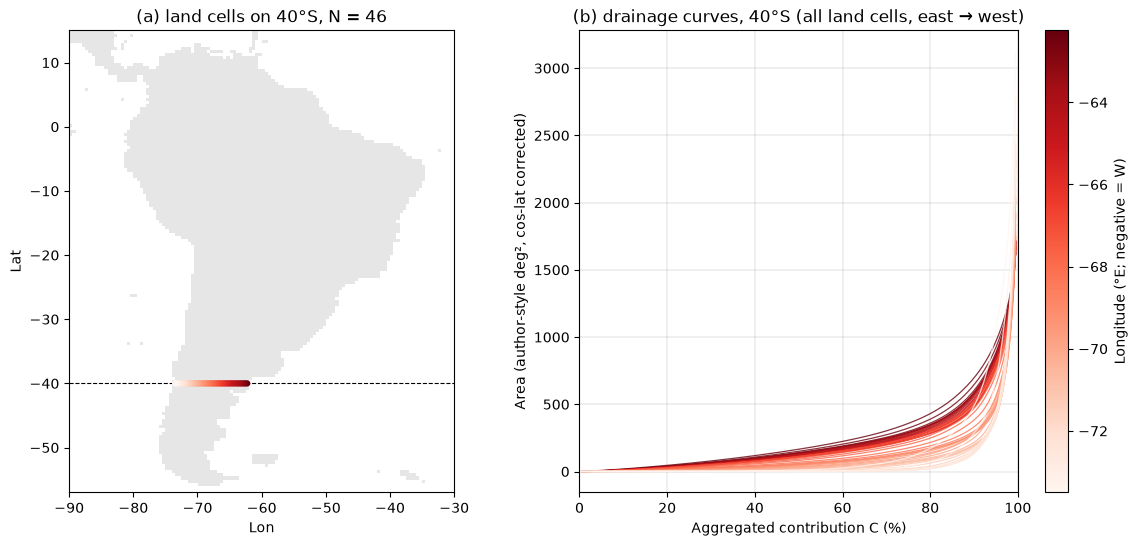

In [110]:
# ---- 5b) 第 5 節的連續格點版本（仿第 2 節）：固定緯線上、(b) 地圖範圍內的全部陸地格點 ----
# 用第 5 節的 s5_LAT 和 s5_EXT，取這條線上每 0.25° 的全部陸地格點（不限兩端、不限沙漠；海上沒有格點，自然留空）
s5c_idx = np.nonzero(np.isclose(c_lat, s5_LAT) & (c_lon >= s5_EXT[0]) & (c_lon <= s5_EXT[1]))[0]
s5c_idx = s5c_idx[np.argsort(-c_lon[s5c_idx])]                       # 東 → 西
s5c_v = c_lon[s5c_idx]                                              # 上色用的經度
print(f"{abs(s5_LAT):g}°{'N' if s5_LAT >= 0 else 'S'} 上、地圖範圍內的陸地格點：{len(s5c_idx)} 個，經度 {s5c_v.min():g}～{s5c_v.max():g}；"
      f"區域 { {r: int((c_rg[s5c_idx] == r).sum()) for r in np.unique(c_rg[s5c_idx])} }")

s5c_A = curves_for(s5c_idx)                                          # 第 3 節定義的函式（和第 2 節同一個算法）

# 顏色：Reds_r，經度/緯度數值越大越淺、越小越深
s5c_nrm = Normalize(s5c_v.min(), s5c_v.max()); s5c_cmp = plt.cm.Reds
fig, axs = plt.subplots(1, 2, figsize=(14, 6), gridspec_kw={"width_ratios": [0.8, 1]})
ax = axs[0]
ax.imshow(np.where(g > 0, 1, 0), cmap=dcm, vmin=-0.5, vmax=3.5,       # 只畫陸地（灰）
          extent=(b.left, b.right, b.bottom, b.top), interpolation="nearest")
ax.axhline(s5_LAT, c="k", lw=0.8, ls="--")                              # 固定的緯線
ax.scatter(c_lon[s5c_idx], c_lat[s5c_idx], c=s5c_v, cmap=s5c_cmp, norm=s5c_nrm, s=12, zorder=3)
ax.set_xlim(s5_EXT[0], s5_EXT[1]); ax.set_ylim(s5_EXT[2], s5_EXT[3]); ax.set_xlabel("Lon"); ax.set_ylabel("Lat")
ax.set_title(f"(a) land cells on {abs(s5_LAT):g}°{'N' if s5_LAT >= 0 else 'S'}, N = {len(s5c_idx)}")
ax = axs[1]
for yy, v in zip(s5c_A, s5c_v):
    ax.plot(tr_X, yy, c=s5c_cmp(s5c_nrm(v)), lw=0.9, alpha=0.8)
ax.set_xlim(0, 100); ax.set_xlabel("Aggregated contribution C (%)")
ax.set_ylabel("Area (author-style deg², cos-lat corrected)")
ax.grid(lw=0.3, c="0.7"); ax.set_title(f"(b) drainage curves, {abs(s5_LAT):g}°{'N' if s5_LAT >= 0 else 'S'} (all land cells, east → west)")
fig.colorbar(mcm.ScalarMappable(s5c_nrm, s5c_cmp), ax=ax, label="Longitude (°E; negative = W)")
plt.savefig(FIG / "SA_curves" / f"sa_{abs(s5_LAT):g}S_E2W_curves_continuous.png", dpi=150, bbox_inches="tight")
plt.show()

## 6) 122°E 由南往北（20°N → 26°N）的曲線演變（同第 4、5 節做法，改成南北向）

固定經度 122°E，緯度從 20°N 到 26°N 取 6 個點，由南往北，畫法和第 4、5 節一模一樣：

- **取點**：`np.linspace(20, 26, 6)` = 20, 21.2, 22.4, 23.6, 24.8, 26 不在 0.25° 網格上，所以四捨五入到最近的 0.25°：**20, 21.25, 22.5, 23.5, 24.75, 26°N**。
- ⚠️ **nc 只有陸地格點**：122°E 在 20～26°N 整段都在海上（台灣東岸約 121.5～121.9°E），照目前參數每個點都會被跳過，程式會停下來提示你改 `s6_LON`（例如 121.25 或 120.75°E）。
- **(a)** 各點的曲線，x 只看 C = 50–100%，顏色由淺紅（南端）到深紅（北端）。
- **(b)** 各點位置（東亞，lon 100～145、lat 0～40，底圖只畫陸地），虛線是南北兩端的緯線，箭頭是取點順序（由南往北）。
- **(c)** 南端和北端兩條曲線的完整 0–100%。
- 最後列出每個點的 AR6 區域、是否碰到 Köppen 沙漠（BWh/BWk）、轉折點與 C = 50 / 80 / 90% 需要的面積。

重用第 3 節的 `curves_for`、`turning`，變數用 `s6_` 開頭。圖存在 `../Figure/Asia_curves/`。

  (121.25, 25.25) 沒有格點，跳過
  (121.25, 25.5) 沒有格點，跳過
  (121.25, 25.75) 沒有格點，跳過
7 個點：23.5°N(EAS)、23.75°N(EAS)、24°N(EAS)、24.25°N(EAS)、24.5°N(EAS)、24.75°N(EAS)、25°N(EAS)
區域 [np.str_('EAS')]；碰到沙漠的點：無


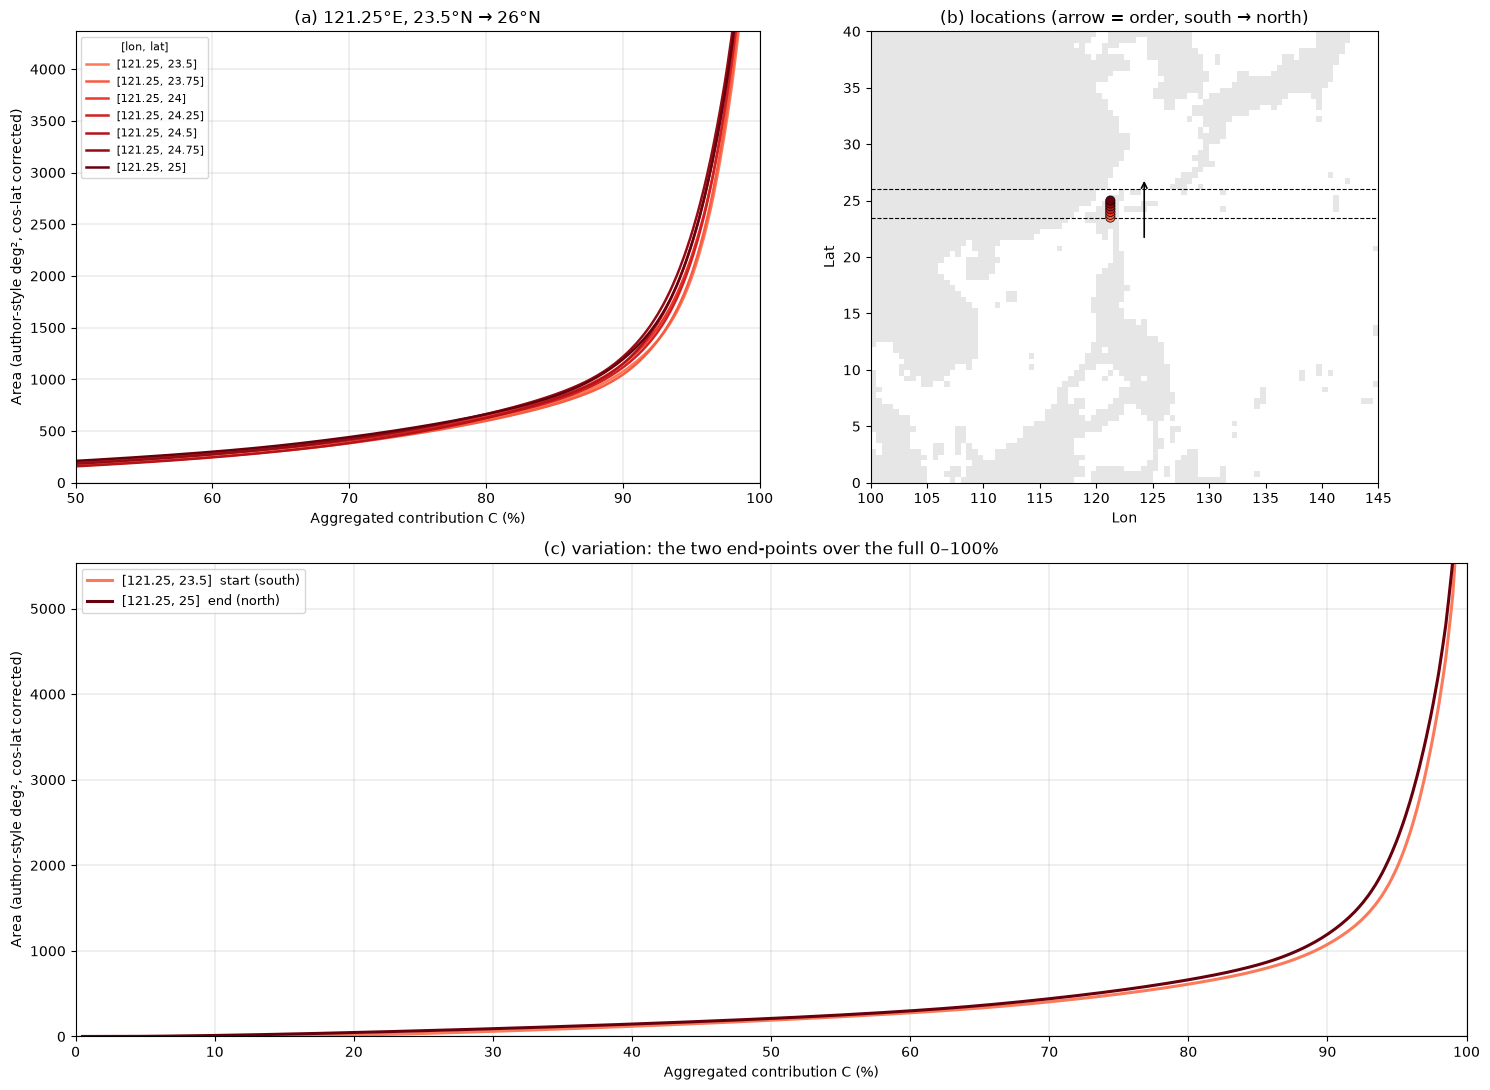

             點    區域   沙漠     轉折點 C(%)      A50      A80      A90
[121.25, 23.5]   EAS    否         14.6      190      611     1075
[121.25, 23.75]   EAS    否         16.6      164      598     1046
  [121.25, 24]   EAS    否         14.4      198      645     1149
[121.25, 24.25]   EAS    否         14.9      187      628     1114
[121.25, 24.5]   EAS    否         19.0      158      625     1149
[121.25, 24.75]   EAS    否         13.6      184      664     1217
  [121.25, 25]   EAS    否          5.1      211      663     1194


In [111]:
# ---- 6) 122°E 由南往北（20°N → 26°N）的排水曲線演變（同第 4、5 節，改成南北向剖面）----
# 需要先跑過 setup、第 1 節（c_lat/c_lon/c_rg、hit_bwh/hit_bwk）、第 2 節（deg2_km2、x_lv、tr_X）、第 3 節（curves_for、turning）
# ⚠️ nc 只有陸地格點：122°E 在 20～26°N 整段都在海上（台灣東岸約 121.5～121.9°E），
#    照這組參數會全部跳過。想畫台灣，可改 s6_LON（例如 121.25 或 120.75）或改 s6_LAT_S/N/N_PT
(FIG / "Asia_curves").mkdir(parents=True, exist_ok=True)
s6_LON, s6_LAT_S, s6_LAT_N, s6_NPT = 121.25, 23.5, 26.0, 0.25         # 固定經度，緯度範圍與點數
s6_want = np.round(np.arange(s6_LAT_S, s6_LAT_N, s6_NPT) * 4) / 4  # 20, 21.2, ... → 四捨五入到 0.25° 網格：20, 21.25, 22.5, 23.5, 24.75, 26（南 → 北）
s6_idx = []
for la in s6_want:
    k = np.nonzero(np.isclose(c_lon, s6_LON) & np.isclose(c_lat, la))[0]
    if len(k): s6_idx.append(k[0])
    else: print(f"  ({s6_LON:g}, {la:g}) 沒有格點，跳過")
s6_idx = np.array(s6_idx, dtype=int)
if len(s6_idx) < 2:
    raise ValueError(f"{s6_LON:g}°E 在 {s6_LAT_S:g}～{s6_LAT_N:g}°N 只有 {len(s6_idx)} 個陸地格點，畫不出剖面，請改 s6_LON 或緯度範圍")
s6_lon, s6_lat = c_lon[s6_idx], c_lat[s6_idx]
s6_desert = (hit_bwh | hit_bwk)[s6_idx]                           # 是否碰到 Köppen 沙漠（BWh + BWk）
print(f"{len(s6_idx)} 個點：" + "、".join(f"{la:g}°N({r})" for la, r in zip(s6_lat, c_rg[s6_idx])))
print(f"區域 {sorted(set(c_rg[s6_idx]))}；碰到沙漠的點：{[f'{la:g}°N' for la in s6_lat[s6_desert]] or '無'}")

s6_A = curves_for(s6_idx)                                          # 第 3 節定義的函式

# 顏色：起點（南端）淺紅 → 終點（北端）深紅
s6_col = plt.cm.Reds(np.linspace(0.45, 1.0, len(s6_idx)))
s6_lab = [f"[{lo:g}, {la:g}]" for lo, la in zip(s6_lon, s6_lat)]
s6_EXT = (100, 145, 0, 40)                                         # 東亞（west, east, south, north）

fig = plt.figure(figsize=(15, 11))
gs = fig.add_gridspec(2, 2, height_ratios=[1, 1.05])
# (a) 曲線，x 只看 50–100%
ax = fig.add_subplot(gs[0, 0])
for yy, c, l in zip(s6_A, s6_col, s6_lab):
    ax.plot(tr_X, yy, c=c, lw=1.8, label=l)
ax.set_xlim(50, 100); ax.set_ylim(0, np.interp(98, tr_X, s6_A.max(0)))
ax.set_xlabel("Aggregated contribution C (%)"); ax.set_ylabel("Area (author-style deg², cos-lat corrected)")
ax.grid(lw=0.3, c="0.7"); ax.legend(fontsize=8, title="[lon, lat]", title_fontsize=8)
ax.set_title(f"(a) {s6_LON:g}°E, {s6_LAT_S:g}°N → {s6_LAT_N:g}°N")
# (b) 點的位置
ax = fig.add_subplot(gs[0, 1])
ax.imshow(np.where(g > 0, 1, 0), cmap=dcm, vmin=-0.5, vmax=3.5,       # 只畫陸地（灰），不畫沙漠
          extent=(b.left, b.right, b.bottom, b.top), interpolation="nearest")
for la in (s6_LAT_S, s6_LAT_N):                                   # 剖面的南、北端緯線（20°N、26°N）
    ax.axhline(la, c="k", lw=0.8, ls="--")
ax.scatter(s6_lon, s6_lat, c=s6_col, s=45, edgecolors="k", linewidths=0.5, zorder=3)
ax.annotate("", xy=(s6_LON + 3, s6_lat[-1] + 2), xytext=(s6_LON + 3, s6_lat[0] - 2),   # 由南往北，畫在經度 +3° 旁
            arrowprops=dict(arrowstyle="->", lw=1.2))
ax.set_xlim(s6_EXT[0], s6_EXT[1]); ax.set_ylim(s6_EXT[2], s6_EXT[3]); ax.set_xlabel("Lon"); ax.set_ylabel("Lat")
ax.set_title("(b) locations (arrow = order, south → north)")
# (c) 兩個端點的完整曲線（0–100%）
ax = fig.add_subplot(gs[1, :])
for i in (0, len(s6_idx) - 1):
    ax.plot(tr_X, s6_A[i], c=s6_col[i], lw=2.2, label=f"{s6_lab[i]}  {'start (south)' if i == 0 else 'end (north)'}")
ax.set_xlim(0, 100); ax.set_ylim(0, np.interp(99, tr_X, s6_A[[0, -1]].max(0)))
ax.set_xticks(range(0, 101, 10))
ax.set_xlabel("Aggregated contribution C (%)"); ax.set_ylabel("Area (author-style deg², cos-lat corrected)")
ax.grid(lw=0.3, c="0.7"); ax.legend(fontsize=9)
ax.set_title("(c) variation: the two end-points over the full 0–100%")
plt.tight_layout()
plt.savefig(FIG / "Asia_curves" / "tw_122E_S2N_curves.png", dpi=150, bbox_inches="tight")
plt.show()

# 轉折點（第 3 節的 turning）與 A50 / A80 / A90
print(f"{'點':>14} {'區域':>5} {'沙漠':>4} {'轉折點 C(%)':>12} {'A50':>8} {'A80':>8} {'A90':>8}")
for l, r, d, yy in zip(s6_lab, c_rg[s6_idx], s6_desert, s6_A):
    print(f"{l:>14} {r:>5} {'是' if d else '否':>4} {turning(tr_X, yy):12.1f} "
          + " ".join(f"{np.interp(q, tr_X, yy):8.0f}" for q in (50, 80, 90)))

121.25°E 上、地圖範圍內的陸地格點：58 個，緯度 0.5～37.5；區域 {np.str_('EAS'): 29, np.str_('SEA'): 29}


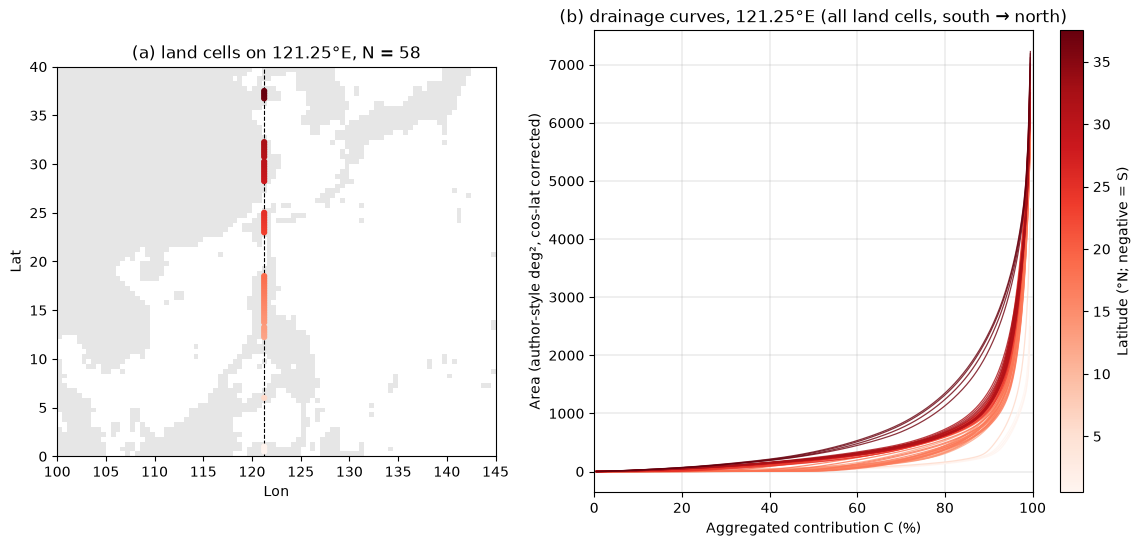

In [112]:
# ---- 6b) 第 6 節的連續格點版本（仿第 2 節）：固定經線上、(b) 地圖範圍內的全部陸地格點 ----
# 用第 6 節的 s6_LON 和 s6_EXT，取這條線上每 0.25° 的全部陸地格點（不限兩端、不限沙漠；海上沒有格點，自然留空）
s6c_idx = np.nonzero(np.isclose(c_lon, s6_LON) & (c_lat >= s6_EXT[2]) & (c_lat <= s6_EXT[3]))[0]
s6c_idx = s6c_idx[np.argsort(c_lat[s6c_idx])]                       # 南 → 北
s6c_v = c_lat[s6c_idx]                                              # 上色用的緯度
print(f"{abs(s6_LON):g}°{'E' if s6_LON >= 0 else 'W'} 上、地圖範圍內的陸地格點：{len(s6c_idx)} 個，緯度 {s6c_v.min():g}～{s6c_v.max():g}；"
      f"區域 { {r: int((c_rg[s6c_idx] == r).sum()) for r in np.unique(c_rg[s6c_idx])} }")

s6c_A = curves_for(s6c_idx)                                          # 第 3 節定義的函式（和第 2 節同一個算法）

# 顏色：Reds_r，經度/緯度數值越大越淺、越小越深
s6c_nrm = Normalize(s6c_v.min(), s6c_v.max()); s6c_cmp = plt.cm.Reds
fig, axs = plt.subplots(1, 2, figsize=(14, 6), gridspec_kw={"width_ratios": [0.8, 1]})
ax = axs[0]
ax.imshow(np.where(g > 0, 1, 0), cmap=dcm, vmin=-0.5, vmax=3.5,       # 只畫陸地（灰）
          extent=(b.left, b.right, b.bottom, b.top), interpolation="nearest")
ax.axvline(s6_LON, c="k", lw=0.8, ls="--")                              # 固定的經線
ax.scatter(c_lon[s6c_idx], c_lat[s6c_idx], c=s6c_v, cmap=s6c_cmp, norm=s6c_nrm, s=12, zorder=3)
ax.set_xlim(s6_EXT[0], s6_EXT[1]); ax.set_ylim(s6_EXT[2], s6_EXT[3]); ax.set_xlabel("Lon"); ax.set_ylabel("Lat")
ax.set_title(f"(a) land cells on {abs(s6_LON):g}°{'E' if s6_LON >= 0 else 'W'}, N = {len(s6c_idx)}")
ax = axs[1]
for yy, v in zip(s6c_A, s6c_v):
    ax.plot(tr_X, yy, c=s6c_cmp(s6c_nrm(v)), lw=0.9, alpha=0.8)
ax.set_xlim(0, 100); ax.set_xlabel("Aggregated contribution C (%)")
ax.set_ylabel("Area (author-style deg², cos-lat corrected)")
ax.grid(lw=0.3, c="0.7"); ax.set_title(f"(b) drainage curves, {abs(s6_LON):g}°{'E' if s6_LON >= 0 else 'W'} (all land cells, south → north)")
fig.colorbar(mcm.ScalarMappable(s6c_nrm, s6c_cmp), ax=ax, label="Latitude (°N; negative = S)")
plt.savefig(FIG / "Asia_curves" / f"tw_{s6_LON:g}E_S2N_curves_continuous.png", dpi=150, bbox_inches="tight")
plt.show()

## 7) 澳洲 15°S 由東往西（145°E → 125.5°E） 的曲線演變（同第 4、5 節做法）

固定緯度，在澳洲陸地的東、西兩端之間每隔 `s7_STEP` 度取一點（對齊 0.25° 網格）；參數都在 code cell 第一行（`s7_` 開頭），改那一行就能換範圍或點數。

- **陸地範圍**（nc 的陸地格點）：125.5～135.5°E（NAU）、141.75～145.25°E（NAU，約克角半島）。
- **取的 6 個點**：145、142、139、136、133、130、127°E（每 3°，共 7 點）。
- **跳過的點**：139°E、136°E 落在卡本塔利亞灣（15°S 的陸地在 135.5～141.75°E 斷開），會被跳過，實際畫 5 個點（海上的點會印出並跳過；少於 2 個點就停下來）。
- **(a)** 各點的曲線，x 只看 C = 50–100%，顏色由淺紅（起點）到深紅（終點）。
- **(b)** 各點位置（澳洲，lon 110～157、lat −45～−8，第 7～10 節共用），虛線是東、西兩端的經線，箭頭是取點順序（east → west）。
- **(c)** 起點和終點兩條曲線的完整 0–100%。
- 最後列出每個點的 AR6 區域、是否碰到 Köppen 沙漠（BWh/BWk）、轉折點與 C = 50 / 80 / 90% 需要的面積。

重用第 3 節的 `curves_for`、`turning`。圖存在 `../Figure/Australia_curves/`。

  (139, -15) 沒有格點（海上），跳過
  (136, -15) 沒有格點（海上），跳過
5 個點：145°E(NAU)、142°E(NAU)、133°E(NAU)、130°E(NAU)、127°E(NAU)
區域 [np.str_('NAU')]；碰到沙漠的點：無


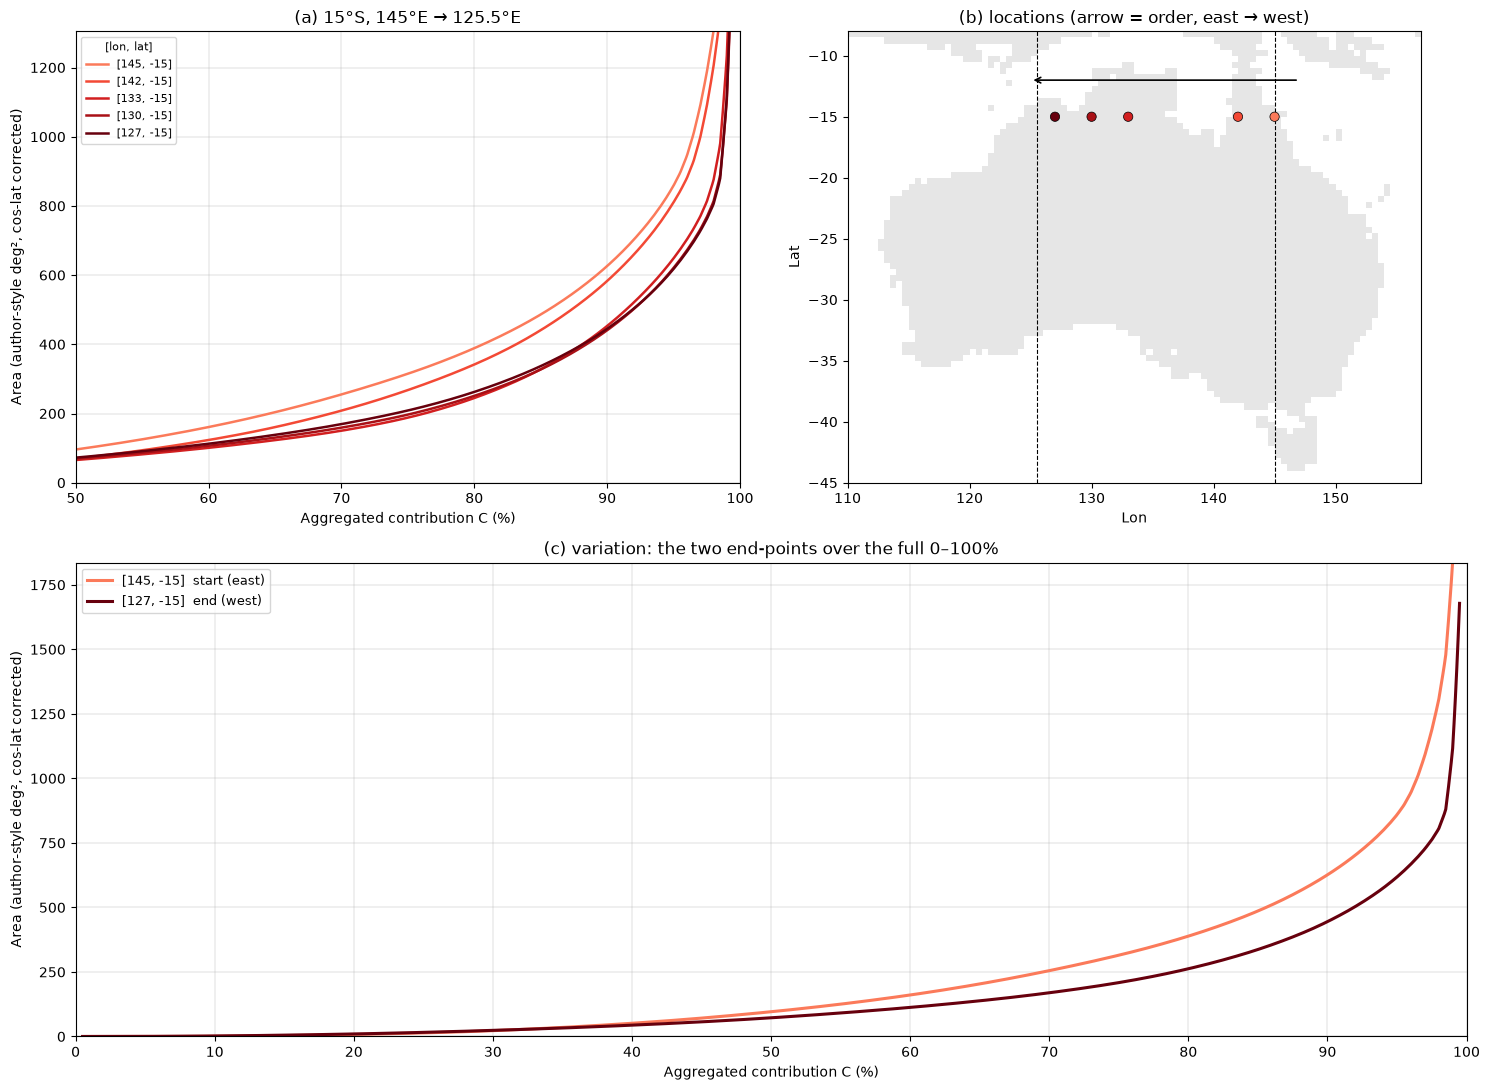

             點    區域   沙漠     轉折點 C(%)      A50      A80      A90
    [145, -15]   NAU    否         95.3       96      389      626
    [142, -15]   NAU    否         96.1       70      342      583
    [133, -15]   NAU    否         75.2       66      245      453
    [130, -15]   NAU    否         75.2       69      251      441
    [127, -15]   NAU    否         97.7       72      262      445


In [113]:
# ---- 7) 澳洲 15°S 由東往西（145°E → 125.5°E） 的排水曲線演變（同第 4、5 節模板）----
s7_LAT, s7_LON_E, s7_LON_W, s7_STEP = -15.0, 145.0, 125.5, 3.0      # 固定緯度、東端、西端、每隔幾度一點（改這裡）
# 需要先跑過 setup、第 1 節（c_lat/c_lon/c_rg、hit_bwh/hit_bwk）、第 2 節（deg2_km2、x_lv、tr_X）、第 3 節（curves_for、turning）
(FIG / "Australia_curves").mkdir(parents=True, exist_ok=True)
s7_want = np.round(np.arange(s7_LON_E, s7_LON_W - 1e-9, -s7_STEP) * 4) / 4   # 東 → 西，對齊 0.25° 網格
s7_idx = []
for lo in s7_want:
    k = np.nonzero(np.isclose(c_lat, s7_LAT) & np.isclose(c_lon, lo))[0]
    if len(k): s7_idx.append(k[0])
    else: print(f"  ({lo:g}, {s7_LAT:g}) 沒有格點（海上），跳過")
s7_idx = np.array(s7_idx, dtype=int)
if len(s7_idx) < 2:
    raise ValueError(f"{abs(s7_LAT):g}°S 在 {s7_LON_W:g}～{s7_LON_E:g}°E 只有 {len(s7_idx)} 個陸地格點，畫不出剖面，請改參數")
s7_lon, s7_lat = c_lon[s7_idx], c_lat[s7_idx]
s7_desert = (hit_bwh | hit_bwk)[s7_idx]                         # 是否碰到 Köppen 沙漠（BWh + BWk）
print(f"{len(s7_idx)} 個點：" + "、".join(f"{lo:g}°E({r})" for lo, r in zip(s7_lon, c_rg[s7_idx])))
print(f"區域 {sorted(set(c_rg[s7_idx]))}；碰到沙漠的點：{[f'{lo:g}°E' for lo in s7_lon[s7_desert]] or '無'}")
s7_TITLE = f"(a) {abs(s7_LAT):g}°S, {s7_LON_E:g}°E → {s7_LON_W:g}°E"
s7_PNG = f"aus_{abs(s7_LAT):g}S_E2W_curves.png"

s7_A = curves_for(s7_idx)                                          # 第 3 節定義的函式

# 顏色：起點淺紅 → 終點深紅
s7_col = plt.cm.Reds(np.linspace(0.45, 1.0, len(s7_idx)))
s7_lab = [f"[{lo:g}, {la:g}]" for lo, la in zip(s7_lon, s7_lat)]
s7_EXT = (110, 157, -45, -8)                                      # 整個澳洲（west, east, south, north），第 7～10 節共用

fig = plt.figure(figsize=(15, 11))
gs = fig.add_gridspec(2, 2, height_ratios=[1, 1.05])
# (a) 曲線，x 只看 50–100%
ax = fig.add_subplot(gs[0, 0])
for yy, c, l in zip(s7_A, s7_col, s7_lab):
    ax.plot(tr_X, yy, c=c, lw=1.8, label=l)
ax.set_xlim(50, 100); ax.set_ylim(0, np.interp(98, tr_X, s7_A.max(0)))
ax.set_xlabel("Aggregated contribution C (%)"); ax.set_ylabel("Area (author-style deg², cos-lat corrected)")
ax.grid(lw=0.3, c="0.7"); ax.legend(fontsize=8, title="[lon, lat]", title_fontsize=8)
ax.set_title(s7_TITLE)
# (b) 點的位置
ax = fig.add_subplot(gs[0, 1])
ax.imshow(np.where(g > 0, 1, 0), cmap=dcm, vmin=-0.5, vmax=3.5,       # 只畫陸地（灰），不畫沙漠
          extent=(b.left, b.right, b.bottom, b.top), interpolation="nearest")
for lo in (s7_LON_E, s7_LON_W):                                # 剖面的東、西端經線
    ax.axvline(lo, c="k", lw=0.8, ls="--")
ax.annotate("", xy=(s7_lon[-1] - 2, s7_LAT + 3), xytext=(s7_lon[0] + 2, s7_LAT + 3),   # 由東往西
            arrowprops=dict(arrowstyle="->", lw=1.2))
ax.scatter(s7_lon, s7_lat, c=s7_col, s=45, edgecolors="k", linewidths=0.5, zorder=3)
ax.set_xlim(s7_EXT[0], s7_EXT[1]); ax.set_ylim(s7_EXT[2], s7_EXT[3]); ax.set_xlabel("Lon"); ax.set_ylabel("Lat")
ax.set_title("(b) locations (arrow = order, east → west)")
# (c) 兩個端點的完整曲線（0–100%）
ax = fig.add_subplot(gs[1, :])
for i in (0, len(s7_idx) - 1):
    ax.plot(tr_X, s7_A[i], c=s7_col[i], lw=2.2, label=f"{s7_lab[i]}  {'start (east)' if i == 0 else 'end (west)'}")
ax.set_xlim(0, 100); ax.set_ylim(0, np.interp(99, tr_X, s7_A[[0, -1]].max(0)))
ax.set_xticks(range(0, 101, 10))
ax.set_xlabel("Aggregated contribution C (%)"); ax.set_ylabel("Area (author-style deg², cos-lat corrected)")
ax.grid(lw=0.3, c="0.7"); ax.legend(fontsize=9)
ax.set_title("(c) variation: the two end-points over the full 0–100%")
plt.tight_layout()
plt.savefig(FIG / "Australia_curves" / s7_PNG, dpi=150, bbox_inches="tight")
plt.show()

# 轉折點（第 3 節的 turning）與 A50 / A80 / A90
print(f"{'點':>14} {'區域':>5} {'沙漠':>4} {'轉折點 C(%)':>12} {'A50':>8} {'A80':>8} {'A90':>8}")
for l, r, d, yy in zip(s7_lab, c_rg[s7_idx], s7_desert, s7_A):
    print(f"{l:>14} {r:>5} {'是' if d else '否':>4} {turning(tr_X, yy):12.1f} "
          + " ".join(f"{np.interp(q, tr_X, yy):8.0f}" for q in (50, 80, 90)))

15°S 上、地圖範圍內的陸地格點：56 個，經度 125.5～145.25；區域 {np.str_('NAU'): 56}


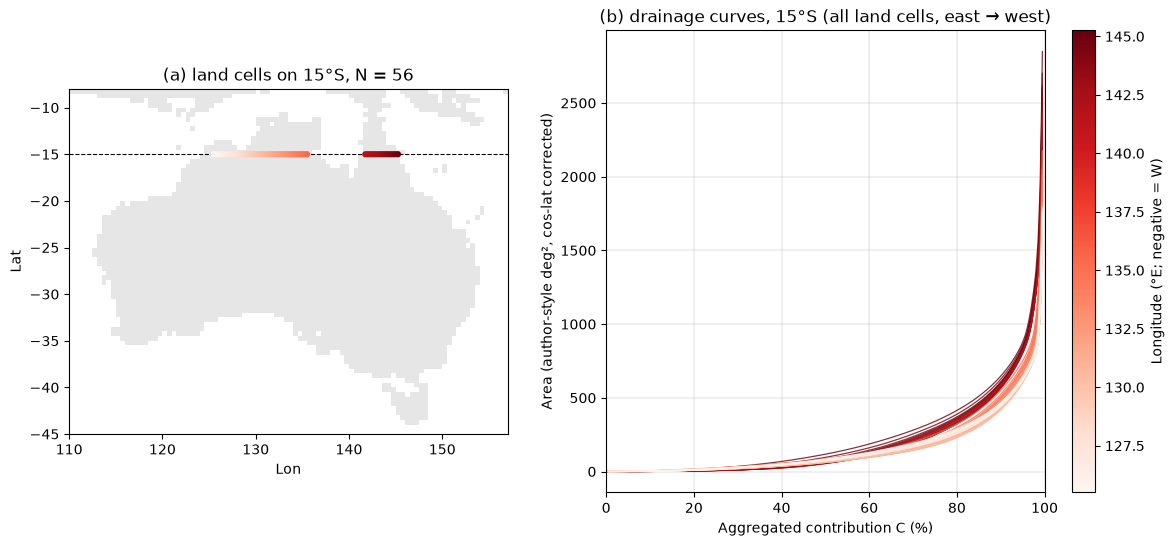

In [114]:
# ---- 7b) 第 7 節的連續格點版本（仿第 2 節）：固定緯線上、(b) 地圖範圍內的全部陸地格點 ----
# 用第 7 節的 s7_LAT 和 s7_EXT，取這條線上每 0.25° 的全部陸地格點（不限兩端、不限沙漠；海上沒有格點，自然留空）
s7c_idx = np.nonzero(np.isclose(c_lat, s7_LAT) & (c_lon >= s7_EXT[0]) & (c_lon <= s7_EXT[1]))[0]
s7c_idx = s7c_idx[np.argsort(-c_lon[s7c_idx])]                       # 東 → 西
s7c_v = c_lon[s7c_idx]                                              # 上色用的經度
print(f"{abs(s7_LAT):g}°{'N' if s7_LAT >= 0 else 'S'} 上、地圖範圍內的陸地格點：{len(s7c_idx)} 個，經度 {s7c_v.min():g}～{s7c_v.max():g}；"
      f"區域 { {r: int((c_rg[s7c_idx] == r).sum()) for r in np.unique(c_rg[s7c_idx])} }")

s7c_A = curves_for(s7c_idx)                                          # 第 3 節定義的函式（和第 2 節同一個算法）

# 顏色：Reds_r，經度/緯度數值越大越淺、越小越深
s7c_nrm = Normalize(s7c_v.min(), s7c_v.max()); s7c_cmp = plt.cm.Reds
fig, axs = plt.subplots(1, 2, figsize=(14, 6), gridspec_kw={"width_ratios": [0.8, 1]})
ax = axs[0]
ax.imshow(np.where(g > 0, 1, 0), cmap=dcm, vmin=-0.5, vmax=3.5,       # 只畫陸地（灰）
          extent=(b.left, b.right, b.bottom, b.top), interpolation="nearest")
ax.axhline(s7_LAT, c="k", lw=0.8, ls="--")                              # 固定的緯線
ax.scatter(c_lon[s7c_idx], c_lat[s7c_idx], c=s7c_v, cmap=s7c_cmp, norm=s7c_nrm, s=12, zorder=3)
ax.set_xlim(s7_EXT[0], s7_EXT[1]); ax.set_ylim(s7_EXT[2], s7_EXT[3]); ax.set_xlabel("Lon"); ax.set_ylabel("Lat")
ax.set_title(f"(a) land cells on {abs(s7_LAT):g}°{'N' if s7_LAT >= 0 else 'S'}, N = {len(s7c_idx)}")
ax = axs[1]
for yy, v in zip(s7c_A, s7c_v):
    ax.plot(tr_X, yy, c=s7c_cmp(s7c_nrm(v)), lw=0.9, alpha=0.8)
ax.set_xlim(0, 100); ax.set_xlabel("Aggregated contribution C (%)")
ax.set_ylabel("Area (author-style deg², cos-lat corrected)")
ax.grid(lw=0.3, c="0.7"); ax.set_title(f"(b) drainage curves, {abs(s7_LAT):g}°{'N' if s7_LAT >= 0 else 'S'} (all land cells, east → west)")
fig.colorbar(mcm.ScalarMappable(s7c_nrm, s7c_cmp), ax=ax, label="Longitude (°E; negative = W)")
plt.savefig(FIG / "Australia_curves" / s7_PNG.replace(".png", "_continuous.png"), dpi=150, bbox_inches="tight")
plt.show()

## 8) 澳洲 30°S 由東往西（153°E → 115°E） 的曲線演變（同第 4、5 節做法）

固定緯度，在澳洲陸地的東、西兩端之間每隔 `s8_STEP` 度取一點（對齊 0.25° 網格）；參數都在 code cell 第一行（`s8_` 開頭），改那一行就能換範圍或點數。

- **陸地範圍**（nc 的陸地格點）：115～153°E，中間沒有斷開（SAU/CAU/EAU）。
- **取的 6 個點**：153、148、143、138、133、128、123、118°E（每 5°，共 8 點）。
- **跳過的點**：沒有，8 點都在陸地上（海上的點會印出並跳過；少於 2 個點就停下來）。
- **(a)** 各點的曲線，x 只看 C = 50–100%，顏色由淺紅（起點）到深紅（終點）。
- **(b)** 各點位置（澳洲，lon 110～157、lat −45～−8，第 7～10 節共用），虛線是東、西兩端的經線，箭頭是取點順序（east → west）。
- **(c)** 起點和終點兩條曲線的完整 0–100%。
- 最後列出每個點的 AR6 區域、是否碰到 Köppen 沙漠（BWh/BWk）、轉折點與 C = 50 / 80 / 90% 需要的面積。

重用第 3 節的 `curves_for`、`turning`。圖存在 `../Figure/Australia_curves/`。

8 個點：153°E(EAU)、148°E(EAU)、143°E(CAU)、138°E(SAU)、133°E(SAU)、128°E(SAU)、123°E(SAU)、118°E(SAU)
區域 [np.str_('CAU'), np.str_('EAU'), np.str_('SAU')]；碰到沙漠的點：['143°E', '138°E', '133°E', '128°E', '123°E', '118°E']


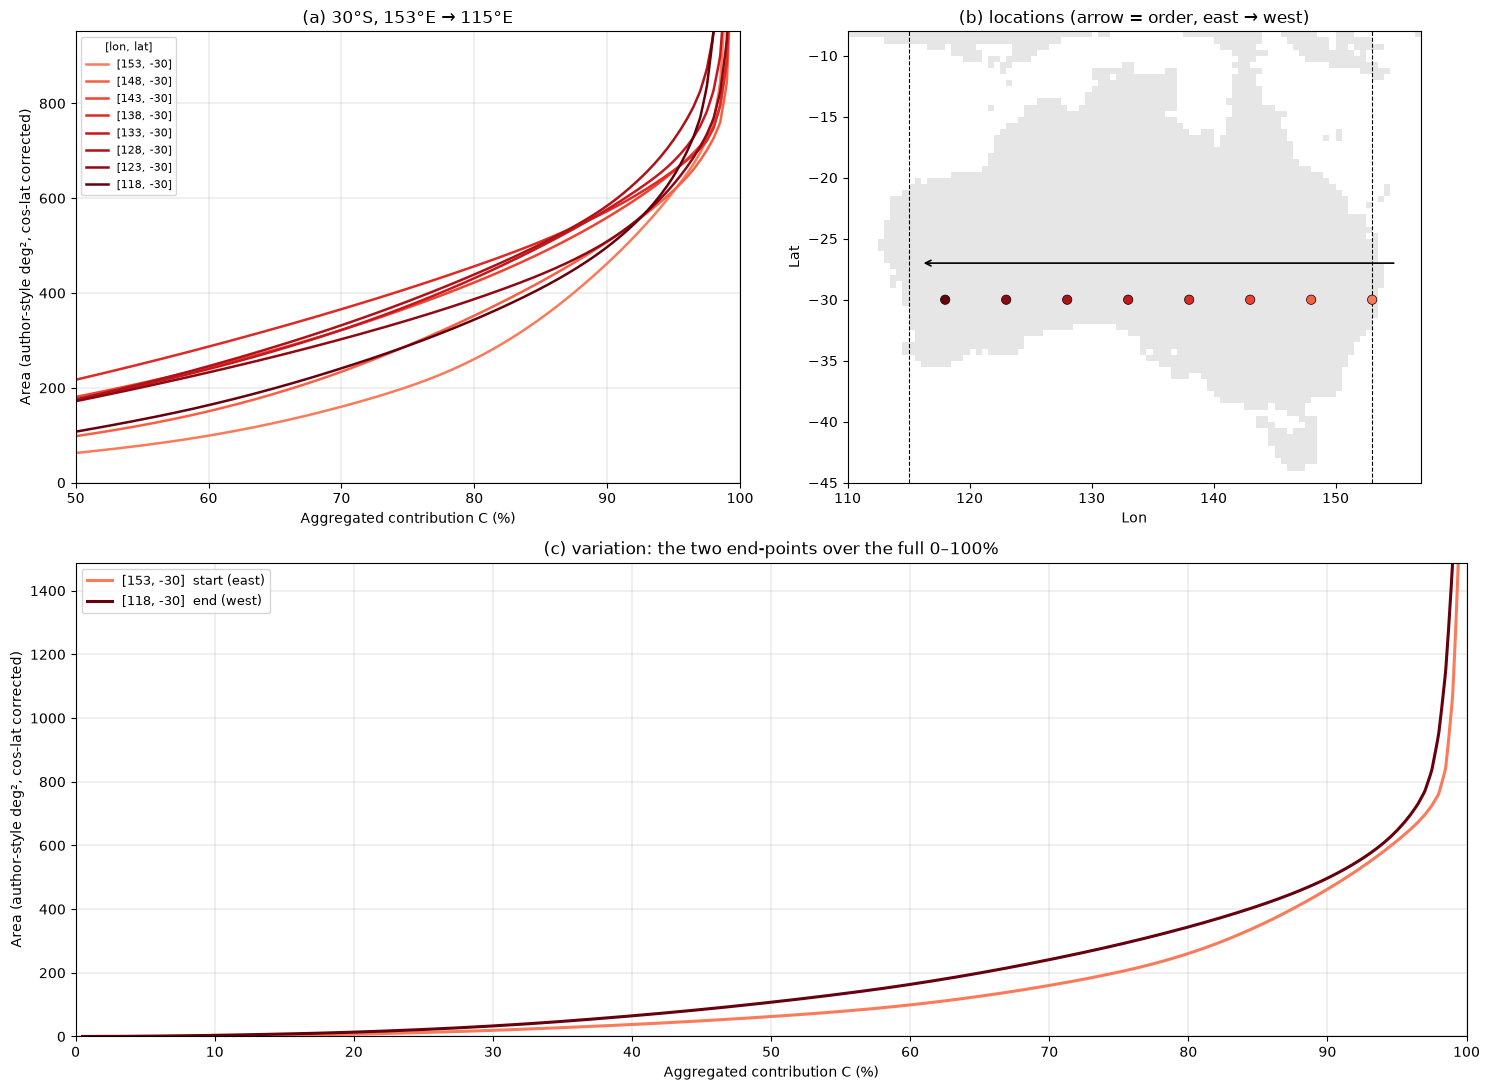

             點    區域   沙漠     轉折點 C(%)      A50      A80      A90
    [153, -30]   EAU    否         77.3       63      261      462
    [148, -30]   EAU    否         59.0       98      352      508
    [143, -30]   CAU    是         97.9      181      422      559
    [138, -30]   SAU    是          5.8      217      456      573
    [133, -30]   SAU    是         16.9      175      431      576
    [128, -30]   SAU    是         96.8      176      439      584
    [123, -30]   SAU    是          4.3      172      387      509
    [118, -30]   SAU    是         96.3      108      344      497


In [115]:
# ---- 8) 澳洲 30°S 由東往西（153°E → 115°E） 的排水曲線演變（同第 4、5 節模板）----
s8_LAT, s8_LON_E, s8_LON_W, s8_STEP = -30.0, 153.0, 115.0, 5.0      # 固定緯度、東端、西端、每隔幾度一點（改這裡）
# 需要先跑過 setup、第 1 節（c_lat/c_lon/c_rg、hit_bwh/hit_bwk）、第 2 節（deg2_km2、x_lv、tr_X）、第 3 節（curves_for、turning）
(FIG / "Australia_curves").mkdir(parents=True, exist_ok=True)
s8_want = np.round(np.arange(s8_LON_E, s8_LON_W - 1e-9, -s8_STEP) * 4) / 4   # 東 → 西，對齊 0.25° 網格
s8_idx = []
for lo in s8_want:
    k = np.nonzero(np.isclose(c_lat, s8_LAT) & np.isclose(c_lon, lo))[0]
    if len(k): s8_idx.append(k[0])
    else: print(f"  ({lo:g}, {s8_LAT:g}) 沒有格點（海上），跳過")
s8_idx = np.array(s8_idx, dtype=int)
if len(s8_idx) < 2:
    raise ValueError(f"{abs(s8_LAT):g}°S 在 {s8_LON_W:g}～{s8_LON_E:g}°E 只有 {len(s8_idx)} 個陸地格點，畫不出剖面，請改參數")
s8_lon, s8_lat = c_lon[s8_idx], c_lat[s8_idx]
s8_desert = (hit_bwh | hit_bwk)[s8_idx]                         # 是否碰到 Köppen 沙漠（BWh + BWk）
print(f"{len(s8_idx)} 個點：" + "、".join(f"{lo:g}°E({r})" for lo, r in zip(s8_lon, c_rg[s8_idx])))
print(f"區域 {sorted(set(c_rg[s8_idx]))}；碰到沙漠的點：{[f'{lo:g}°E' for lo in s8_lon[s8_desert]] or '無'}")
s8_TITLE = f"(a) {abs(s8_LAT):g}°S, {s8_LON_E:g}°E → {s8_LON_W:g}°E"
s8_PNG = f"aus_{abs(s8_LAT):g}S_E2W_curves.png"

s8_A = curves_for(s8_idx)                                          # 第 3 節定義的函式

# 顏色：起點淺紅 → 終點深紅
s8_col = plt.cm.Reds(np.linspace(0.45, 1.0, len(s8_idx)))
s8_lab = [f"[{lo:g}, {la:g}]" for lo, la in zip(s8_lon, s8_lat)]
s8_EXT = (110, 157, -45, -8)                                      # 整個澳洲（west, east, south, north），第 7～10 節共用

fig = plt.figure(figsize=(15, 11))
gs = fig.add_gridspec(2, 2, height_ratios=[1, 1.05])
# (a) 曲線，x 只看 50–100%
ax = fig.add_subplot(gs[0, 0])
for yy, c, l in zip(s8_A, s8_col, s8_lab):
    ax.plot(tr_X, yy, c=c, lw=1.8, label=l)
ax.set_xlim(50, 100); ax.set_ylim(0, np.interp(98, tr_X, s8_A.max(0)))
ax.set_xlabel("Aggregated contribution C (%)"); ax.set_ylabel("Area (author-style deg², cos-lat corrected)")
ax.grid(lw=0.3, c="0.7"); ax.legend(fontsize=8, title="[lon, lat]", title_fontsize=8)
ax.set_title(s8_TITLE)
# (b) 點的位置
ax = fig.add_subplot(gs[0, 1])
ax.imshow(np.where(g > 0, 1, 0), cmap=dcm, vmin=-0.5, vmax=3.5,       # 只畫陸地（灰），不畫沙漠
          extent=(b.left, b.right, b.bottom, b.top), interpolation="nearest")
for lo in (s8_LON_E, s8_LON_W):                                # 剖面的東、西端經線
    ax.axvline(lo, c="k", lw=0.8, ls="--")
ax.annotate("", xy=(s8_lon[-1] - 2, s8_LAT + 3), xytext=(s8_lon[0] + 2, s8_LAT + 3),   # 由東往西
            arrowprops=dict(arrowstyle="->", lw=1.2))
ax.scatter(s8_lon, s8_lat, c=s8_col, s=45, edgecolors="k", linewidths=0.5, zorder=3)
ax.set_xlim(s8_EXT[0], s8_EXT[1]); ax.set_ylim(s8_EXT[2], s8_EXT[3]); ax.set_xlabel("Lon"); ax.set_ylabel("Lat")
ax.set_title("(b) locations (arrow = order, east → west)")
# (c) 兩個端點的完整曲線（0–100%）
ax = fig.add_subplot(gs[1, :])
for i in (0, len(s8_idx) - 1):
    ax.plot(tr_X, s8_A[i], c=s8_col[i], lw=2.2, label=f"{s8_lab[i]}  {'start (east)' if i == 0 else 'end (west)'}")
ax.set_xlim(0, 100); ax.set_ylim(0, np.interp(99, tr_X, s8_A[[0, -1]].max(0)))
ax.set_xticks(range(0, 101, 10))
ax.set_xlabel("Aggregated contribution C (%)"); ax.set_ylabel("Area (author-style deg², cos-lat corrected)")
ax.grid(lw=0.3, c="0.7"); ax.legend(fontsize=9)
ax.set_title("(c) variation: the two end-points over the full 0–100%")
plt.tight_layout()
plt.savefig(FIG / "Australia_curves" / s8_PNG, dpi=150, bbox_inches="tight")
plt.show()

# 轉折點（第 3 節的 turning）與 A50 / A80 / A90
print(f"{'點':>14} {'區域':>5} {'沙漠':>4} {'轉折點 C(%)':>12} {'A50':>8} {'A80':>8} {'A90':>8}")
for l, r, d, yy in zip(s8_lab, c_rg[s8_idx], s8_desert, s8_A):
    print(f"{l:>14} {r:>5} {'是' if d else '否':>4} {turning(tr_X, yy):12.1f} "
          + " ".join(f"{np.interp(q, tr_X, yy):8.0f}" for q in (50, 80, 90)))

30°S 上、地圖範圍內的陸地格點：153 個，經度 115～153；區域 {np.str_('CAU'): 22, np.str_('EAU'): 30, np.str_('SAU'): 101}


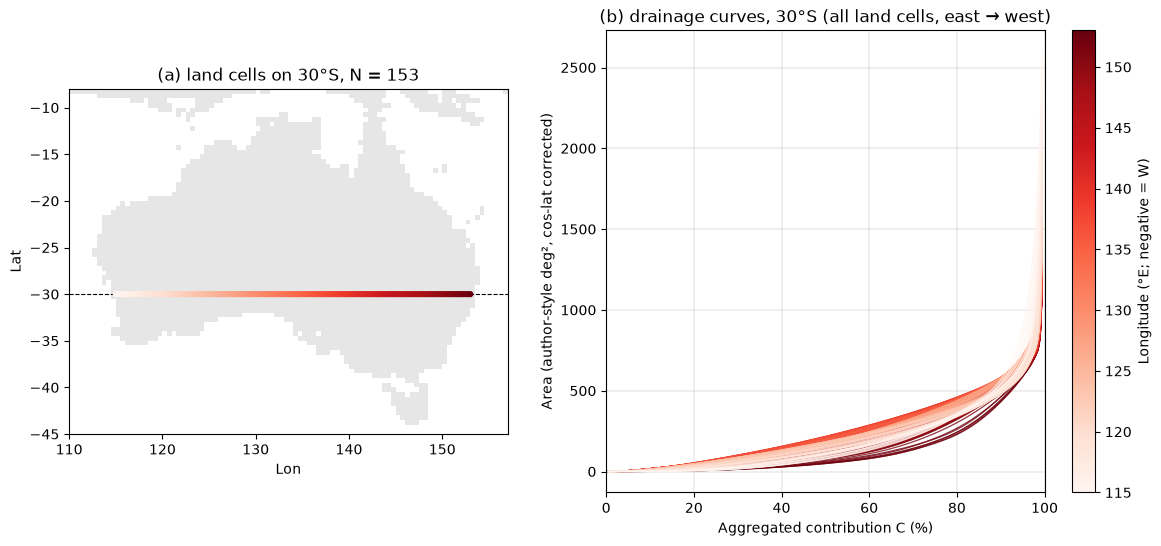

In [116]:
# ---- 8b) 第 8 節的連續格點版本（仿第 2 節）：固定緯線上、(b) 地圖範圍內的全部陸地格點 ----
# 用第 8 節的 s8_LAT 和 s8_EXT，取這條線上每 0.25° 的全部陸地格點（不限兩端、不限沙漠；海上沒有格點，自然留空）
s8c_idx = np.nonzero(np.isclose(c_lat, s8_LAT) & (c_lon >= s8_EXT[0]) & (c_lon <= s8_EXT[1]))[0]
s8c_idx = s8c_idx[np.argsort(-c_lon[s8c_idx])]                       # 東 → 西
s8c_v = c_lon[s8c_idx]                                              # 上色用的經度
print(f"{abs(s8_LAT):g}°{'N' if s8_LAT >= 0 else 'S'} 上、地圖範圍內的陸地格點：{len(s8c_idx)} 個，經度 {s8c_v.min():g}～{s8c_v.max():g}；"
      f"區域 { {r: int((c_rg[s8c_idx] == r).sum()) for r in np.unique(c_rg[s8c_idx])} }")

s8c_A = curves_for(s8c_idx)                                          # 第 3 節定義的函式（和第 2 節同一個算法）

# 顏色：Reds_r，經度/緯度數值越大越淺、越小越深
s8c_nrm = Normalize(s8c_v.min(), s8c_v.max()); s8c_cmp = plt.cm.Reds
fig, axs = plt.subplots(1, 2, figsize=(14, 6), gridspec_kw={"width_ratios": [0.8, 1]})
ax = axs[0]
ax.imshow(np.where(g > 0, 1, 0), cmap=dcm, vmin=-0.5, vmax=3.5,       # 只畫陸地（灰）
          extent=(b.left, b.right, b.bottom, b.top), interpolation="nearest")
ax.axhline(s8_LAT, c="k", lw=0.8, ls="--")                              # 固定的緯線
ax.scatter(c_lon[s8c_idx], c_lat[s8c_idx], c=s8c_v, cmap=s8c_cmp, norm=s8c_nrm, s=12, zorder=3)
ax.set_xlim(s8_EXT[0], s8_EXT[1]); ax.set_ylim(s8_EXT[2], s8_EXT[3]); ax.set_xlabel("Lon"); ax.set_ylabel("Lat")
ax.set_title(f"(a) land cells on {abs(s8_LAT):g}°{'N' if s8_LAT >= 0 else 'S'}, N = {len(s8c_idx)}")
ax = axs[1]
for yy, v in zip(s8c_A, s8c_v):
    ax.plot(tr_X, yy, c=s8c_cmp(s8c_nrm(v)), lw=0.9, alpha=0.8)
ax.set_xlim(0, 100); ax.set_xlabel("Aggregated contribution C (%)")
ax.set_ylabel("Area (author-style deg², cos-lat corrected)")
ax.grid(lw=0.3, c="0.7"); ax.set_title(f"(b) drainage curves, {abs(s8_LAT):g}°{'N' if s8_LAT >= 0 else 'S'} (all land cells, east → west)")
fig.colorbar(mcm.ScalarMappable(s8c_nrm, s8c_cmp), ax=ax, label="Longitude (°E; negative = W)")
plt.savefig(FIG / "Australia_curves" / s8_PNG.replace(".png", "_continuous.png"), dpi=150, bbox_inches="tight")
plt.show()

## 9) 澳洲 120°E 由北往南（20°S → 33.5°S） 的曲線演變（同第 4、5 節做法）

固定經度，從北岸往內陸，在澳洲陸地的北、南兩端之間每隔 `s9_STEP` 度取一點（對齊 0.25° 網格）；參數都在 code cell 第一行（`s9_` 開頭），改那一行就能換範圍或點數。

- **陸地範圍**（nc 的陸地格點）：20～33.75°S（CAU/SAU）。
- **取的 6 個點**：20、22.5、25、27.5、30、32.5°S（每 2.5°，共 6 點；33.5°S 不在 2.5° 的間隔上，所以最後一點是 32.5°S）。
- **跳過的點**：沒有，6 點都在陸地上（海上的點會印出並跳過；少於 2 個點就停下來）。
- **(a)** 各點的曲線，x 只看 C = 50–100%，顏色由淺紅（起點）到深紅（終點）。
- **(b)** 各點位置（澳洲，lon 110～157、lat −45～−8，第 7～10 節共用），虛線是北、南兩端的緯線，箭頭是取點順序（north → south）。
- **(c)** 起點和終點兩條曲線的完整 0–100%。
- 最後列出每個點的 AR6 區域、是否碰到 Köppen 沙漠（BWh/BWk）、轉折點與 C = 50 / 80 / 90% 需要的面積。

重用第 3 節的 `curves_for`、`turning`。圖存在 `../Figure/Australia_curves/`。

6 個點：20°S(CAU)、22.5°S(CAU)、25°S(CAU)、27.5°S(CAU)、30°S(SAU)、32.5°S(SAU)
區域 [np.str_('CAU'), np.str_('SAU')]；碰到沙漠的點：['20°S', '22.5°S', '25°S', '27.5°S', '30°S']


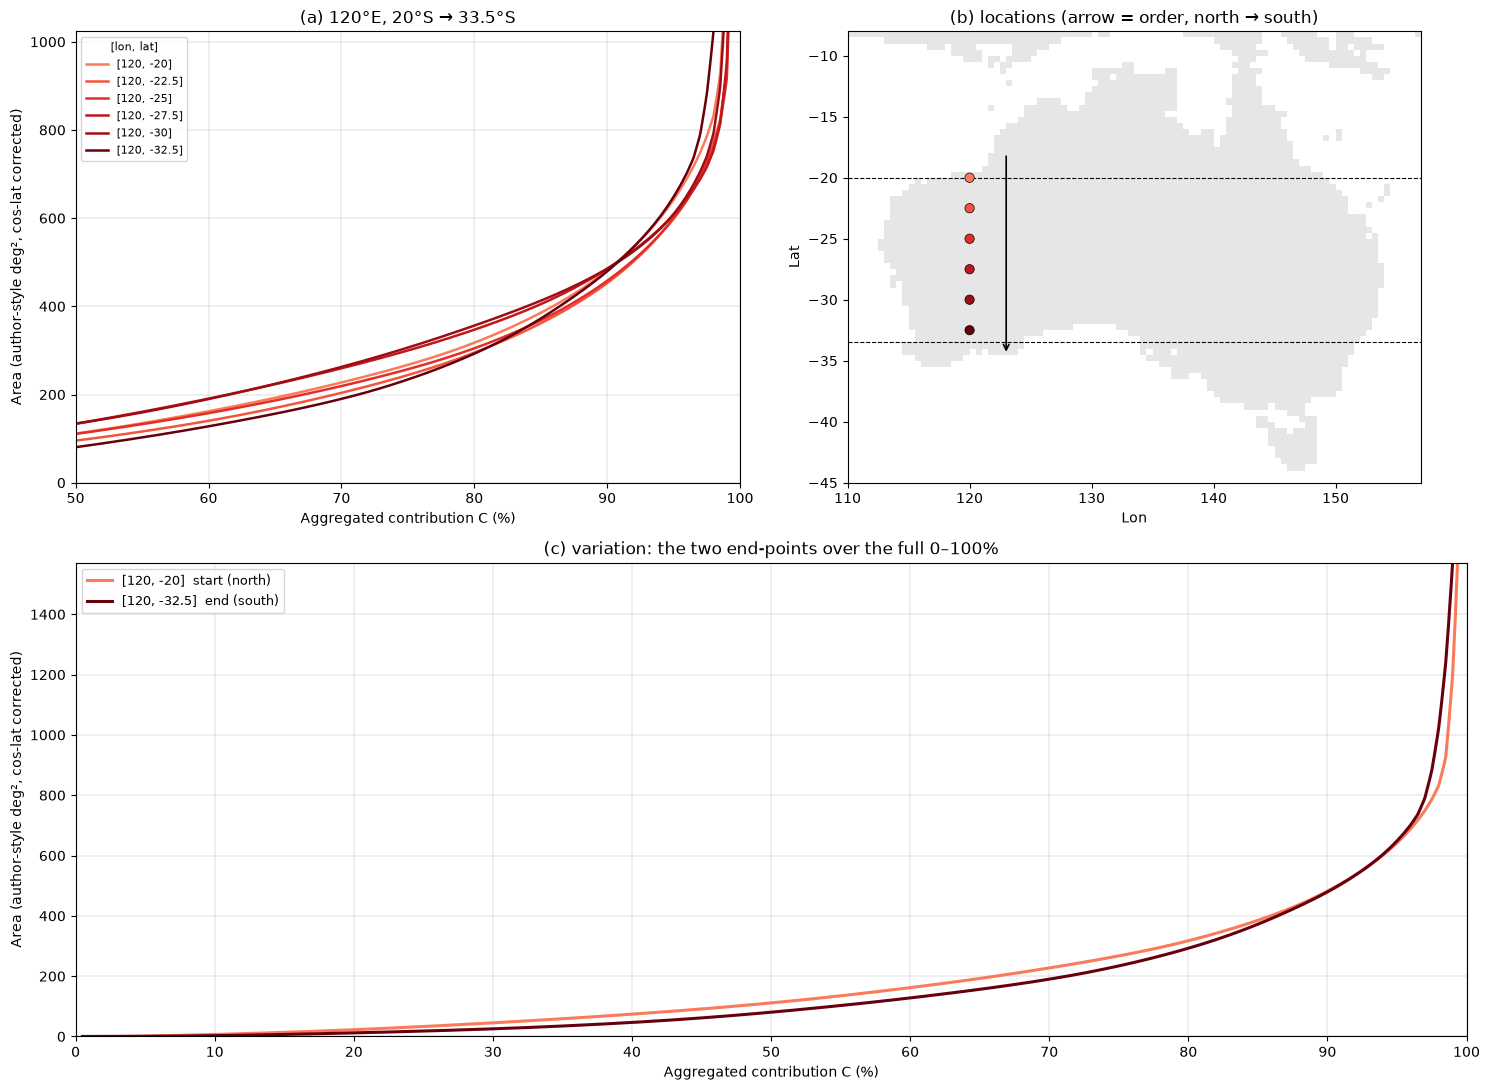

             點    區域   沙漠     轉折點 C(%)      A50      A80      A90
    [120, -20]   CAU    是          3.3      111      317      482
  [120, -22.5]   CAU    是          nan       95      295      453
    [120, -25]   CAU    是         97.8      111      305      458
  [120, -27.5]   CAU    是         97.7      134      347      485
    [120, -30]   SAU    是         97.1      134      356      486
  [120, -32.5]   SAU    否         72.5       81      293      479


In [117]:
# ---- 9) 澳洲 120°E 由北往南（20°S → 33.5°S） 的排水曲線演變（同第 4、5 節模板）----
s9_LON, s9_LAT_N, s9_LAT_S, s9_STEP = 120.0, -20.0, -33.5, 2.5      # 固定經度、北端、南端、每隔幾度一點（改這裡）
# 需要先跑過 setup、第 1 節（c_lat/c_lon/c_rg、hit_bwh/hit_bwk）、第 2 節（deg2_km2、x_lv、tr_X）、第 3 節（curves_for、turning）
(FIG / "Australia_curves").mkdir(parents=True, exist_ok=True)
s9_want = np.round(np.arange(s9_LAT_N, s9_LAT_S - 1e-9, -s9_STEP) * 4) / 4   # 北 → 南，對齊 0.25° 網格
s9_idx = []
for la in s9_want:
    k = np.nonzero(np.isclose(c_lon, s9_LON) & np.isclose(c_lat, la))[0]
    if len(k): s9_idx.append(k[0])
    else: print(f"  ({s9_LON:g}, {la:g}) 沒有格點（海上），跳過")
s9_idx = np.array(s9_idx, dtype=int)
if len(s9_idx) < 2:
    raise ValueError(f"{s9_LON:g}°E 在 {abs(s9_LAT_N):g}～{abs(s9_LAT_S):g}°S 只有 {len(s9_idx)} 個陸地格點，畫不出剖面，請改參數")
s9_lon, s9_lat = c_lon[s9_idx], c_lat[s9_idx]
s9_desert = (hit_bwh | hit_bwk)[s9_idx]                         # 是否碰到 Köppen 沙漠（BWh + BWk）
print(f"{len(s9_idx)} 個點：" + "、".join(f"{abs(la):g}°S({r})" for la, r in zip(s9_lat, c_rg[s9_idx])))
print(f"區域 {sorted(set(c_rg[s9_idx]))}；碰到沙漠的點：{[f'{abs(la):g}°S' for la in s9_lat[s9_desert]] or '無'}")
s9_TITLE = f"(a) {s9_LON:g}°E, {abs(s9_LAT_N):g}°S → {abs(s9_LAT_S):g}°S"
s9_PNG = f"aus_{s9_LON:g}E_N2S_curves.png"

s9_A = curves_for(s9_idx)                                          # 第 3 節定義的函式

# 顏色：起點淺紅 → 終點深紅
s9_col = plt.cm.Reds(np.linspace(0.45, 1.0, len(s9_idx)))
s9_lab = [f"[{lo:g}, {la:g}]" for lo, la in zip(s9_lon, s9_lat)]
s9_EXT = (110, 157, -45, -8)                                      # 整個澳洲（west, east, south, north），第 7～10 節共用

fig = plt.figure(figsize=(15, 11))
gs = fig.add_gridspec(2, 2, height_ratios=[1, 1.05])
# (a) 曲線，x 只看 50–100%
ax = fig.add_subplot(gs[0, 0])
for yy, c, l in zip(s9_A, s9_col, s9_lab):
    ax.plot(tr_X, yy, c=c, lw=1.8, label=l)
ax.set_xlim(50, 100); ax.set_ylim(0, np.interp(98, tr_X, s9_A.max(0)))
ax.set_xlabel("Aggregated contribution C (%)"); ax.set_ylabel("Area (author-style deg², cos-lat corrected)")
ax.grid(lw=0.3, c="0.7"); ax.legend(fontsize=8, title="[lon, lat]", title_fontsize=8)
ax.set_title(s9_TITLE)
# (b) 點的位置
ax = fig.add_subplot(gs[0, 1])
ax.imshow(np.where(g > 0, 1, 0), cmap=dcm, vmin=-0.5, vmax=3.5,       # 只畫陸地（灰），不畫沙漠
          extent=(b.left, b.right, b.bottom, b.top), interpolation="nearest")
for la in (s9_LAT_N, s9_LAT_S):                                # 剖面的北、南端緯線
    ax.axhline(la, c="k", lw=0.8, ls="--")
ax.annotate("", xy=(s9_LON + 3, s9_lat[-1] - 2), xytext=(s9_LON + 3, s9_lat[0] + 2),   # 由北往南，畫在經度 +3° 旁
            arrowprops=dict(arrowstyle="->", lw=1.2))
ax.scatter(s9_lon, s9_lat, c=s9_col, s=45, edgecolors="k", linewidths=0.5, zorder=3)
ax.set_xlim(s9_EXT[0], s9_EXT[1]); ax.set_ylim(s9_EXT[2], s9_EXT[3]); ax.set_xlabel("Lon"); ax.set_ylabel("Lat")
ax.set_title("(b) locations (arrow = order, north → south)")
# (c) 兩個端點的完整曲線（0–100%）
ax = fig.add_subplot(gs[1, :])
for i in (0, len(s9_idx) - 1):
    ax.plot(tr_X, s9_A[i], c=s9_col[i], lw=2.2, label=f"{s9_lab[i]}  {'start (north)' if i == 0 else 'end (south)'}")
ax.set_xlim(0, 100); ax.set_ylim(0, np.interp(99, tr_X, s9_A[[0, -1]].max(0)))
ax.set_xticks(range(0, 101, 10))
ax.set_xlabel("Aggregated contribution C (%)"); ax.set_ylabel("Area (author-style deg², cos-lat corrected)")
ax.grid(lw=0.3, c="0.7"); ax.legend(fontsize=9)
ax.set_title("(c) variation: the two end-points over the full 0–100%")
plt.tight_layout()
plt.savefig(FIG / "Australia_curves" / s9_PNG, dpi=150, bbox_inches="tight")
plt.show()

# 轉折點（第 3 節的 turning）與 A50 / A80 / A90
print(f"{'點':>14} {'區域':>5} {'沙漠':>4} {'轉折點 C(%)':>12} {'A50':>8} {'A80':>8} {'A90':>8}")
for l, r, d, yy in zip(s9_lab, c_rg[s9_idx], s9_desert, s9_A):
    print(f"{l:>14} {r:>5} {'是' if d else '否':>4} {turning(tr_X, yy):12.1f} "
          + " ".join(f"{np.interp(q, tr_X, yy):8.0f}" for q in (50, 80, 90)))

120°E 上、地圖範圍內的陸地格點：56 個，緯度 -33.75～-20；區域 {np.str_('CAU'): 40, np.str_('SAU'): 16}


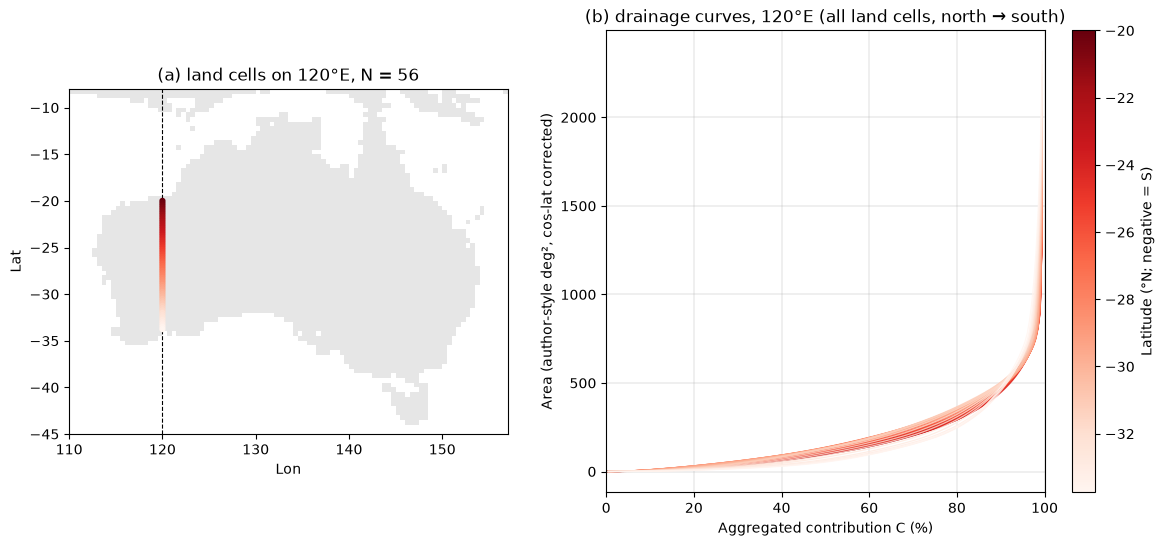

In [118]:
# ---- 9b) 第 9 節的連續格點版本（仿第 2 節）：固定經線上、(b) 地圖範圍內的全部陸地格點 ----
# 用第 9 節的 s9_LON 和 s9_EXT，取這條線上每 0.25° 的全部陸地格點（不限兩端、不限沙漠；海上沒有格點，自然留空）
s9c_idx = np.nonzero(np.isclose(c_lon, s9_LON) & (c_lat >= s9_EXT[2]) & (c_lat <= s9_EXT[3]))[0]
# 篩選：只留澳洲本土（AR6 NAU/CAU/SAU/EAU，且在 15°S 以南），去掉 8.5～10°S 松巴島一帶的島嶼格點（含一格被歸在 NAU 的）
s9c_idx = s9c_idx[np.isin(c_rg[s9c_idx], ["NAU", "CAU", "SAU", "EAU"]) & (c_lat[s9c_idx] < -15)]
s9c_idx = s9c_idx[np.argsort(-c_lat[s9c_idx])]                       # 北 → 南
s9c_v = c_lat[s9c_idx]                                              # 上色用的緯度
print(f"{abs(s9_LON):g}°{'E' if s9_LON >= 0 else 'W'} 上、地圖範圍內的陸地格點：{len(s9c_idx)} 個，緯度 {s9c_v.min():g}～{s9c_v.max():g}；"
      f"區域 { {r: int((c_rg[s9c_idx] == r).sum()) for r in np.unique(c_rg[s9c_idx])} }")

s9c_A = curves_for(s9c_idx)                                          # 第 3 節定義的函式（和第 2 節同一個算法）

# 顏色：Reds_r，經度/緯度數值越大越淺、越小越深
s9c_nrm = Normalize(s9c_v.min(), s9c_v.max()); s9c_cmp = plt.cm.Reds
fig, axs = plt.subplots(1, 2, figsize=(14, 6), gridspec_kw={"width_ratios": [0.8, 1]})
ax = axs[0]
ax.imshow(np.where(g > 0, 1, 0), cmap=dcm, vmin=-0.5, vmax=3.5,       # 只畫陸地（灰）
          extent=(b.left, b.right, b.bottom, b.top), interpolation="nearest")
ax.axvline(s9_LON, c="k", lw=0.8, ls="--")                              # 固定的經線
ax.scatter(c_lon[s9c_idx], c_lat[s9c_idx], c=s9c_v, cmap=s9c_cmp, norm=s9c_nrm, s=12, zorder=3)
ax.set_xlim(s9_EXT[0], s9_EXT[1]); ax.set_ylim(s9_EXT[2], s9_EXT[3]); ax.set_xlabel("Lon"); ax.set_ylabel("Lat")
ax.set_title(f"(a) land cells on {abs(s9_LON):g}°{'E' if s9_LON >= 0 else 'W'}, N = {len(s9c_idx)}")
ax = axs[1]
for yy, v in zip(s9c_A, s9c_v):
    ax.plot(tr_X, yy, c=s9c_cmp(s9c_nrm(v)), lw=0.9, alpha=0.8)
ax.set_xlim(0, 100); ax.set_xlabel("Aggregated contribution C (%)")
ax.set_ylabel("Area (author-style deg², cos-lat corrected)")
ax.grid(lw=0.3, c="0.7"); ax.set_title(f"(b) drainage curves, {abs(s9_LON):g}°{'E' if s9_LON >= 0 else 'W'} (all land cells, north → south)")
fig.colorbar(mcm.ScalarMappable(s9c_nrm, s9c_cmp), ax=ax, label="Latitude (°N; negative = S)")
plt.savefig(FIG / "Australia_curves" / s9_PNG.replace(".png", "_continuous.png"), dpi=150, bbox_inches="tight")
plt.show()

## 10) 澳洲 145°E 由北往南（15°S → 37.5°S） 的曲線演變（同第 4、5 節做法）

固定經度，從北岸往內陸，在澳洲陸地的北、南兩端之間每隔 `aus145_STEP` 度取一點（對齊 0.25° 網格）；參數都在 code cell 第一行（`aus145_` 開頭），改那一行就能換範圍或點數。

- **陸地範圍**（nc 的陸地格點）：15～37.75°S（NAU/CAU/SAU）；塔斯馬尼亞（41～41.75°S）不含。
- **取的 6 個點**：15、19.5、24、28.5、33、37.5°S（每 4.5°，共 6 點）。
- **跳過的點**：沒有，6 點都在陸地上（海上的點會印出並跳過；少於 2 個點就停下來）。
- **(a)** 各點的曲線，x 只看 C = 50–100%，顏色由淺紅（起點）到深紅（終點）。
- **(b)** 各點位置（澳洲，lon 110～157、lat −45～−8，第 7～10 節共用），虛線是北、南兩端的緯線，箭頭是取點順序（north → south）。
- **(c)** 起點和終點兩條曲線的完整 0–100%。
- 最後列出每個點的 AR6 區域、是否碰到 Köppen 沙漠（BWh/BWk）、轉折點與 C = 50 / 80 / 90% 需要的面積。

重用第 3 節的 `curves_for`、`turning`。圖存在 `../Figure/Australia_curves/`。

6 個點：15°S(NAU)、19.5°S(NAU)、24°S(CAU)、28.5°S(CAU)、33°S(SAU)、37.5°S(SAU)
區域 [np.str_('CAU'), np.str_('NAU'), np.str_('SAU')]；碰到沙漠的點：['28.5°S']


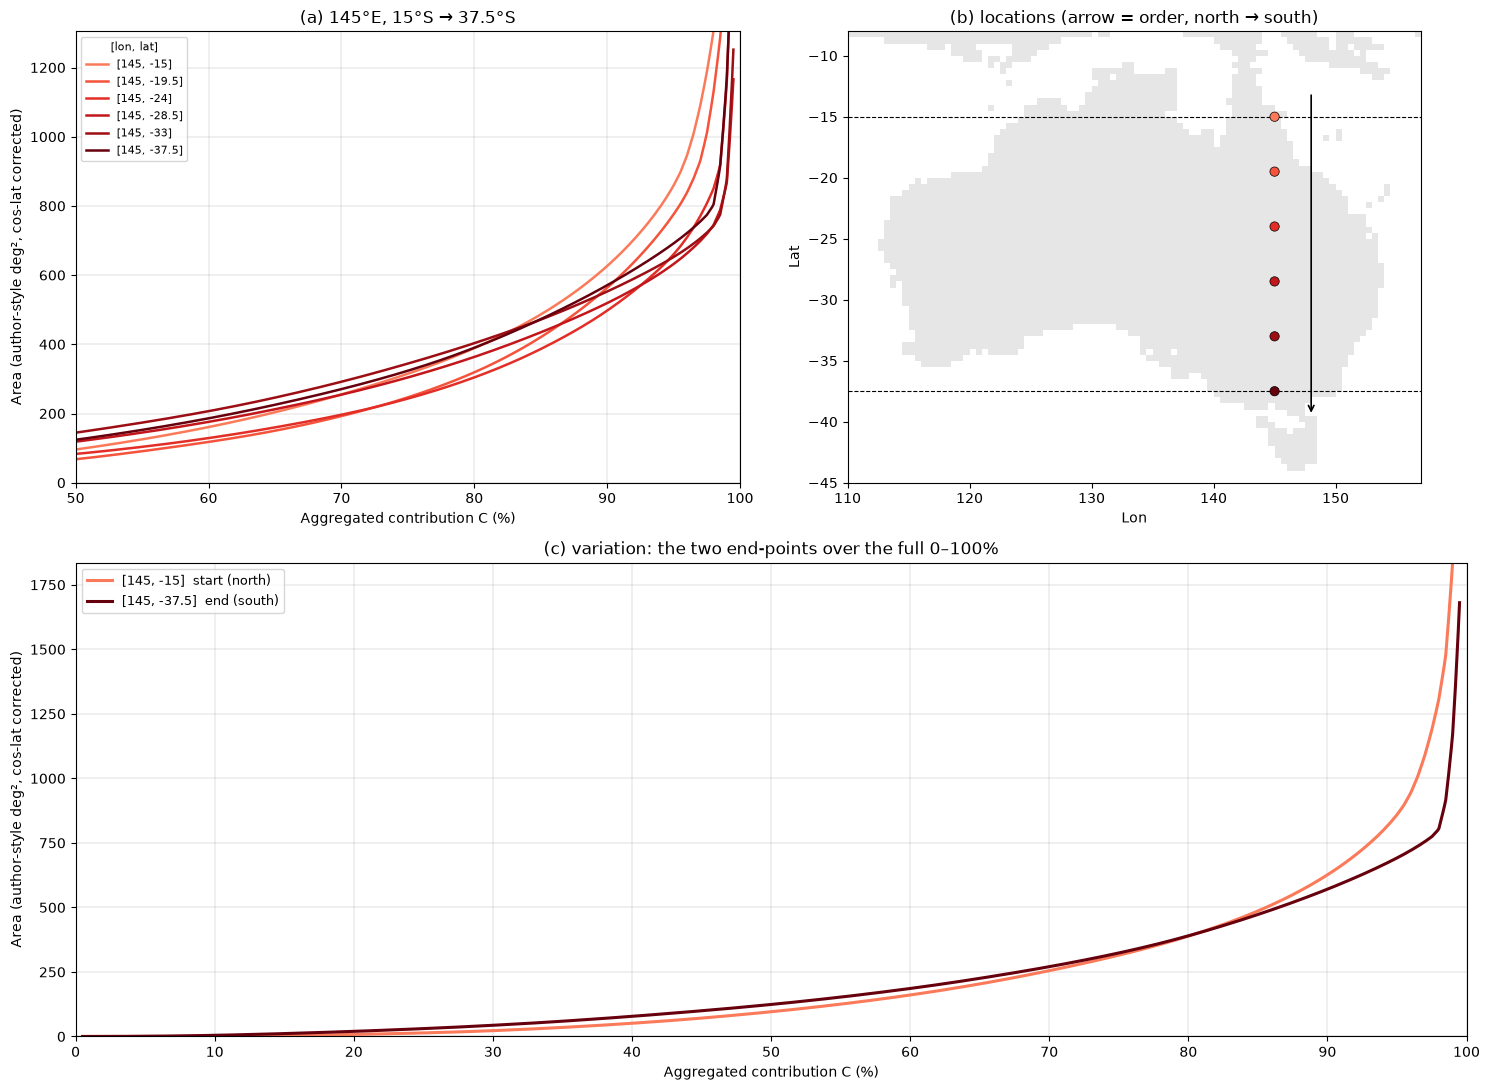

             點    區域   沙漠     轉折點 C(%)      A50      A80      A90
    [145, -15]   NAU    否         95.3       96      389      626
  [145, -19.5]   NAU    否         46.6       68      319      563
    [145, -24]   CAU    否         97.4       83      304      497
  [145, -28.5]   CAU    是         98.0      119      364      519
    [145, -33]   SAU    否         98.0      145      403      553
  [145, -37.5]   SAU    否         77.7      124      390      571


In [119]:
# ---- 10) 澳洲 145°E 由北往南（15°S → 37.5°S） 的排水曲線演變（同第 4、5 節模板）----
aus145_LON, aus145_LAT_N, aus145_LAT_S, aus145_STEP = 145.0, -15.0, -37.5, 4.5      # 固定經度、北端、南端、每隔幾度一點（改這裡）
# 需要先跑過 setup、第 1 節（c_lat/c_lon/c_rg、hit_bwh/hit_bwk）、第 2 節（deg2_km2、x_lv、tr_X）、第 3 節（curves_for、turning）
(FIG / "Australia_curves").mkdir(parents=True, exist_ok=True)
aus145_want = np.round(np.arange(aus145_LAT_N, aus145_LAT_S - 1e-9, -aus145_STEP) * 4) / 4   # 北 → 南，對齊 0.25° 網格
aus145_idx = []
for la in aus145_want:
    k = np.nonzero(np.isclose(c_lon, aus145_LON) & np.isclose(c_lat, la))[0]
    if len(k): aus145_idx.append(k[0])
    else: print(f"  ({aus145_LON:g}, {la:g}) 沒有格點（海上），跳過")
aus145_idx = np.array(aus145_idx, dtype=int)
if len(aus145_idx) < 2:
    raise ValueError(f"{aus145_LON:g}°E 在 {abs(aus145_LAT_N):g}～{abs(aus145_LAT_S):g}°S 只有 {len(aus145_idx)} 個陸地格點，畫不出剖面，請改參數")
aus145_lon, aus145_lat = c_lon[aus145_idx], c_lat[aus145_idx]
aus145_desert = (hit_bwh | hit_bwk)[aus145_idx]                         # 是否碰到 Köppen 沙漠（BWh + BWk）
print(f"{len(aus145_idx)} 個點：" + "、".join(f"{abs(la):g}°S({r})" for la, r in zip(aus145_lat, c_rg[aus145_idx])))
print(f"區域 {sorted(set(c_rg[aus145_idx]))}；碰到沙漠的點：{[f'{abs(la):g}°S' for la in aus145_lat[aus145_desert]] or '無'}")
aus145_TITLE = f"(a) {aus145_LON:g}°E, {abs(aus145_LAT_N):g}°S → {abs(aus145_LAT_S):g}°S"
aus145_PNG = f"aus_{aus145_LON:g}E_N2S_curves.png"

aus145_A = curves_for(aus145_idx)                                          # 第 3 節定義的函式

# 顏色：起點淺紅 → 終點深紅
aus145_col = plt.cm.Reds(np.linspace(0.45, 1.0, len(aus145_idx)))
aus145_lab = [f"[{lo:g}, {la:g}]" for lo, la in zip(aus145_lon, aus145_lat)]
aus145_EXT = (110, 157, -45, -8)                                      # 整個澳洲（west, east, south, north），第 7～10 節共用

fig = plt.figure(figsize=(15, 11))
gs = fig.add_gridspec(2, 2, height_ratios=[1, 1.05])
# (a) 曲線，x 只看 50–100%
ax = fig.add_subplot(gs[0, 0])
for yy, c, l in zip(aus145_A, aus145_col, aus145_lab):
    ax.plot(tr_X, yy, c=c, lw=1.8, label=l)
ax.set_xlim(50, 100); ax.set_ylim(0, np.interp(98, tr_X, aus145_A.max(0)))
ax.set_xlabel("Aggregated contribution C (%)"); ax.set_ylabel("Area (author-style deg², cos-lat corrected)")
ax.grid(lw=0.3, c="0.7"); ax.legend(fontsize=8, title="[lon, lat]", title_fontsize=8)
ax.set_title(aus145_TITLE)
# (b) 點的位置
ax = fig.add_subplot(gs[0, 1])
ax.imshow(np.where(g > 0, 1, 0), cmap=dcm, vmin=-0.5, vmax=3.5,       # 只畫陸地（灰），不畫沙漠
          extent=(b.left, b.right, b.bottom, b.top), interpolation="nearest")
for la in (aus145_LAT_N, aus145_LAT_S):                                # 剖面的北、南端緯線
    ax.axhline(la, c="k", lw=0.8, ls="--")
ax.annotate("", xy=(aus145_LON + 3, aus145_lat[-1] - 2), xytext=(aus145_LON + 3, aus145_lat[0] + 2),   # 由北往南，畫在經度 +3° 旁
            arrowprops=dict(arrowstyle="->", lw=1.2))
ax.scatter(aus145_lon, aus145_lat, c=aus145_col, s=45, edgecolors="k", linewidths=0.5, zorder=3)
ax.set_xlim(aus145_EXT[0], aus145_EXT[1]); ax.set_ylim(aus145_EXT[2], aus145_EXT[3]); ax.set_xlabel("Lon"); ax.set_ylabel("Lat")
ax.set_title("(b) locations (arrow = order, north → south)")
# (c) 兩個端點的完整曲線（0–100%）
ax = fig.add_subplot(gs[1, :])
for i in (0, len(aus145_idx) - 1):
    ax.plot(tr_X, aus145_A[i], c=aus145_col[i], lw=2.2, label=f"{aus145_lab[i]}  {'start (north)' if i == 0 else 'end (south)'}")
ax.set_xlim(0, 100); ax.set_ylim(0, np.interp(99, tr_X, aus145_A[[0, -1]].max(0)))
ax.set_xticks(range(0, 101, 10))
ax.set_xlabel("Aggregated contribution C (%)"); ax.set_ylabel("Area (author-style deg², cos-lat corrected)")
ax.grid(lw=0.3, c="0.7"); ax.legend(fontsize=9)
ax.set_title("(c) variation: the two end-points over the full 0–100%")
plt.tight_layout()
plt.savefig(FIG / "Australia_curves" / aus145_PNG, dpi=150, bbox_inches="tight")
plt.show()

# 轉折點（第 3 節的 turning）與 A50 / A80 / A90
print(f"{'點':>14} {'區域':>5} {'沙漠':>4} {'轉折點 C(%)':>12} {'A50':>8} {'A80':>8} {'A90':>8}")
for l, r, d, yy in zip(aus145_lab, c_rg[aus145_idx], aus145_desert, aus145_A):
    print(f"{l:>14} {r:>5} {'是' if d else '否':>4} {turning(tr_X, yy):12.1f} "
          + " ".join(f"{np.interp(q, tr_X, yy):8.0f}" for q in (50, 80, 90)))

145°E 上、地圖範圍內的陸地格點：92 個，緯度 -37.75～-15；區域 {np.str_('CAU'): 51, np.str_('NAU'): 20, np.str_('SAU'): 21}


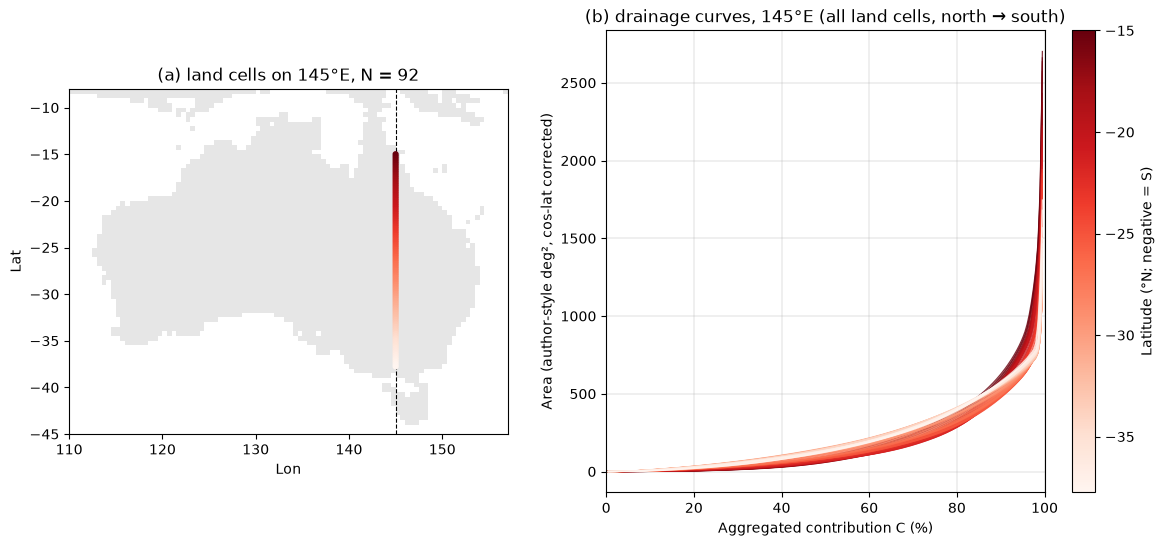

In [120]:
# ---- 10b) 第 10 節的連續格點版本（仿第 2 節）：固定經線上、(b) 地圖範圍內的全部陸地格點 ----
# 用第 10 節的 aus145_LON 和 aus145_EXT，取這條線上每 0.25° 的全部陸地格點（不限兩端、不限沙漠；海上沒有格點，自然留空）
aus145c_idx = np.nonzero(np.isclose(c_lon, aus145_LON) & (c_lat >= aus145_EXT[2]) & (c_lat <= aus145_EXT[3]))[0]
# 篩選：去掉塔斯馬尼亞（39.5°S 以南的格點），只留澳洲本土
aus145c_idx = aus145c_idx[c_lat[aus145c_idx] >= -39.5]
aus145c_idx = aus145c_idx[np.argsort(-c_lat[aus145c_idx])]                       # 北 → 南
aus145c_v = c_lat[aus145c_idx]                                              # 上色用的緯度
print(f"{abs(aus145_LON):g}°{'E' if aus145_LON >= 0 else 'W'} 上、地圖範圍內的陸地格點：{len(aus145c_idx)} 個，緯度 {aus145c_v.min():g}～{aus145c_v.max():g}；"
      f"區域 { {r: int((c_rg[aus145c_idx] == r).sum()) for r in np.unique(c_rg[aus145c_idx])} }")

aus145c_A = curves_for(aus145c_idx)                                          # 第 3 節定義的函式（和第 2 節同一個算法）

# 顏色：Reds_r，經度/緯度數值越大越淺、越小越深
aus145c_nrm = Normalize(aus145c_v.min(), aus145c_v.max()); aus145c_cmp = plt.cm.Reds
fig, axs = plt.subplots(1, 2, figsize=(14, 6), gridspec_kw={"width_ratios": [0.8, 1]})
ax = axs[0]
ax.imshow(np.where(g > 0, 1, 0), cmap=dcm, vmin=-0.5, vmax=3.5,       # 只畫陸地（灰）
          extent=(b.left, b.right, b.bottom, b.top), interpolation="nearest")
ax.axvline(aus145_LON, c="k", lw=0.8, ls="--")                              # 固定的經線
ax.scatter(c_lon[aus145c_idx], c_lat[aus145c_idx], c=aus145c_v, cmap=aus145c_cmp, norm=aus145c_nrm, s=12, zorder=3)
ax.set_xlim(aus145_EXT[0], aus145_EXT[1]); ax.set_ylim(aus145_EXT[2], aus145_EXT[3]); ax.set_xlabel("Lon"); ax.set_ylabel("Lat")
ax.set_title(f"(a) land cells on {abs(aus145_LON):g}°{'E' if aus145_LON >= 0 else 'W'}, N = {len(aus145c_idx)}")
ax = axs[1]
for yy, v in zip(aus145c_A, aus145c_v):
    ax.plot(tr_X, yy, c=aus145c_cmp(aus145c_nrm(v)), lw=0.9, alpha=0.8)
ax.set_xlim(0, 100); ax.set_xlabel("Aggregated contribution C (%)")
ax.set_ylabel("Area (author-style deg², cos-lat corrected)")
ax.grid(lw=0.3, c="0.7"); ax.set_title(f"(b) drainage curves, {abs(aus145_LON):g}°{'E' if aus145_LON >= 0 else 'W'} (all land cells, north → south)")
fig.colorbar(mcm.ScalarMappable(aus145c_nrm, aus145c_cmp), ax=ax, label="Latitude (°N; negative = S)")
plt.savefig(FIG / "Australia_curves" / aus145_PNG.replace(".png", "_continuous.png"), dpi=150, bbox_inches="tight")
plt.show()

## 11) 5°N 全球陸地 6 點的曲線比較（同第 4、5 節做法）

固定 5°N，在全球陸地上挑 6 個點，分散在三大洲，每點盡量選在該段陸地中間、避開海岸。經度清單 `s11_LONS` 在 code cell 第一行，改那一行就能換點，程式會自動由東往西排序並對齊 0.25° 網格。

- **5°N 的陸地段**（nc 的陸地格點）：南美北部 77.25～52.5°W（NWS/NSA）；西非 9～6°W、2.5～1.75°W（WAF）；非洲 5.5～48.25°E（WAF/CAF/NEAF）；蘇門答臘 95.5～97.5°E、馬來半島 100.5～103.25°E、婆羅洲 115～118.75°E、菲律賓 120°E（SEA）。斯里蘭卡（6～10°N）不在 5°N 上。
- **取的 6 個點**（由東往西）：117°E 婆羅洲（SEA）、102°E 馬來半島（SEA）、30°E 南蘇丹（NEAF）、7.5°W 象牙海岸／賴比瑞亞（WAF）、60°W 圭亞那地盾（NSA）、72°W 哥倫比亞（NWS）。
- **(a)** 各點的曲線，x 只看 C = 50–100%，顏色由淺紅（最東）到深紅（最西）。
- **(b)** 全球地圖（lon −180～180、lat −60～60，只畫陸地），虛線是 5°N 緯線；點分得太開所以不畫箭頭，改在每點旁標經度。
- **(c)** 最東和最西兩點的完整 0–100%。
- 最後列出每個點的 AR6 區域、是否碰到 Köppen 沙漠（BWh/BWk）、轉折點與 C = 50 / 80 / 90% 需要的面積。
- 注意：這 6 點分屬不同大陸，不是同一條風路徑上的上下游，(a) 的顏色只代表經度順序。

重用第 3 節的 `curves_for`、`turning`，變數用 `s11_` 開頭。圖存在 `../Figure/Global_curves/`。

6 個點：117°E(SEA)、102°E(SEA)、30°E(NEAF)、7.5°W(WAF)、60°W(NSA)、72°W(NWS)
區域 [np.str_('NEAF'), np.str_('NSA'), np.str_('NWS'), np.str_('SEA'), np.str_('WAF')]；碰到沙漠的點：無


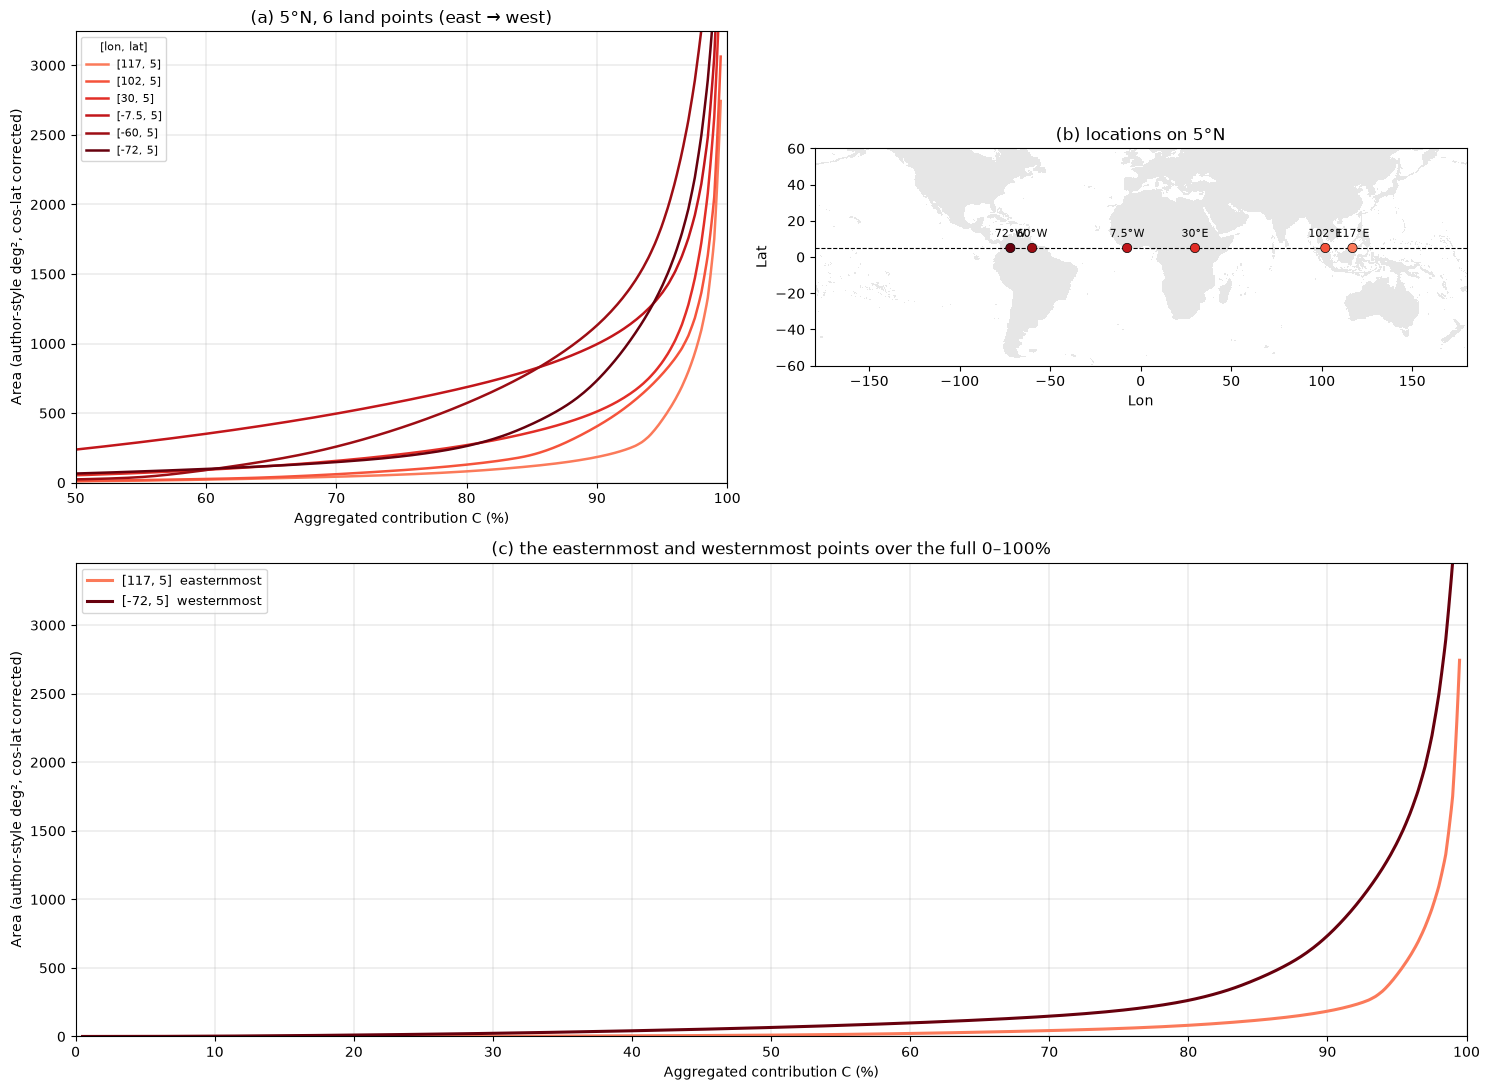

             點    區域   沙漠     轉折點 C(%)      A50      A80      A90
      [117, 5]   SEA    否         92.3       10       82      185
      [102, 5]   SEA    否         63.7       12      130      405
       [30, 5]  NEAF    否         90.3       53      270      511
     [-7.5, 5]   WAF    否         10.3      238      687      996
      [-60, 5]   NSA    否         55.0       24      572     1131
      [-72, 5]   NWS    否         78.7       66      263      735


In [121]:
s11_LAT, s11_LONS = 5.0, [117.0, 102.0, 30.0, -7.5, -60.0, -72.0]   # 固定 5°N；全球陸地上的 6 個經度（由東往西，改這裡）
# ---- 11) 5°N 全球陸地 6 點的排水曲線比較（同第 4、5 節模板）----
# 需要先跑過 setup、第 1 節（c_lat/c_lon/c_rg、hit_bwh/hit_bwk）、第 2 節（deg2_km2、x_lv、tr_X）、第 3 節（curves_for、turning）
(FIG / "Global_curves").mkdir(parents=True, exist_ok=True)
s11_want = np.round(np.sort(np.asarray(s11_LONS, float))[::-1] * 4) / 4   # 由東往西排序，對齊 0.25° 網格
s11_idx = []
for lo in s11_want:
    k = np.nonzero(np.isclose(c_lat, s11_LAT) & np.isclose(c_lon, lo))[0]
    if len(k): s11_idx.append(k[0])
    else: print(f"  ({lo:g}, {s11_LAT:g}) 沒有格點（海上），跳過")
s11_idx = np.array(s11_idx, dtype=int)
if len(s11_idx) < 2:
    raise ValueError(f"{s11_LAT:g}°N 只有 {len(s11_idx)} 個陸地格點，畫不出比較，請改 s11_LONS")
s11_lon, s11_lat = c_lon[s11_idx], c_lat[s11_idx]
s11_desert = (hit_bwh | hit_bwk)[s11_idx]                        # 是否碰到 Köppen 沙漠（BWh + BWk）
lonstr = lambda lo: f"{lo:g}°E" if lo >= 0 else f"{-lo:g}°W"
print(f"{len(s11_idx)} 個點：" + "、".join(f"{lonstr(lo)}({r})" for lo, r in zip(s11_lon, c_rg[s11_idx])))
print(f"區域 {sorted(set(c_rg[s11_idx]))}；碰到沙漠的點：{[lonstr(lo) for lo in s11_lon[s11_desert]] or '無'}")

s11_A = curves_for(s11_idx)                                         # 第 3 節定義的函式

# 顏色：最東淺紅 → 最西深紅
s11_col = plt.cm.Reds(np.linspace(0.45, 1.0, len(s11_idx)))
s11_lab = [f"[{lo:g}, {la:g}]" for lo, la in zip(s11_lon, s11_lat)]
s11_EXT = (-180, 180, -60, 60)                                     # 全球（west, east, south, north）

fig = plt.figure(figsize=(15, 11))
gs = fig.add_gridspec(2, 2, height_ratios=[1, 1.05])
# (a) 曲線，x 只看 50–100%
ax = fig.add_subplot(gs[0, 0])
for yy, c, l in zip(s11_A, s11_col, s11_lab):
    ax.plot(tr_X, yy, c=c, lw=1.8, label=l)
ax.set_xlim(50, 100); ax.set_ylim(0, np.interp(98, tr_X, s11_A.max(0)))
ax.set_xlabel("Aggregated contribution C (%)"); ax.set_ylabel("Area (author-style deg², cos-lat corrected)")
ax.grid(lw=0.3, c="0.7"); ax.legend(fontsize=8, title="[lon, lat]", title_fontsize=8)
ax.set_title(f"(a) {s11_LAT:g}°N, {len(s11_idx)} land points (east → west)")
# (b) 點的位置：全球，只畫 5°N 緯線，不畫箭頭，每點旁標經度
ax = fig.add_subplot(gs[0, 1])
ax.imshow(np.where(g > 0, 1, 0), cmap=dcm, vmin=-0.5, vmax=3.5,       # 只畫陸地（灰），不畫沙漠
          extent=(b.left, b.right, b.bottom, b.top), interpolation="nearest")
ax.axhline(s11_LAT, c="k", lw=0.8, ls="--")                       # 5°N 緯線
ax.scatter(s11_lon, s11_lat, c=s11_col, s=45, edgecolors="k", linewidths=0.5, zorder=3)
for lo, la in zip(s11_lon, s11_lat):
    ax.annotate(lonstr(lo), (lo, la), xytext=(0, 8), textcoords="offset points", ha="center", fontsize=8)
ax.set_xlim(s11_EXT[0], s11_EXT[1]); ax.set_ylim(s11_EXT[2], s11_EXT[3]); ax.set_xlabel("Lon"); ax.set_ylabel("Lat")
ax.set_title(f"(b) locations on {s11_LAT:g}°N")
# (c) 最東和最西兩點的完整曲線（0–100%）
ax = fig.add_subplot(gs[1, :])
for i in (0, len(s11_idx) - 1):
    ax.plot(tr_X, s11_A[i], c=s11_col[i], lw=2.2, label=f"{s11_lab[i]}  {'easternmost' if i == 0 else 'westernmost'}")
ax.set_xlim(0, 100); ax.set_ylim(0, np.interp(99, tr_X, s11_A[[0, -1]].max(0)))
ax.set_xticks(range(0, 101, 10))
ax.set_xlabel("Aggregated contribution C (%)"); ax.set_ylabel("Area (author-style deg², cos-lat corrected)")
ax.grid(lw=0.3, c="0.7"); ax.legend(fontsize=9)
ax.set_title("(c) the easternmost and westernmost points over the full 0–100%")
plt.tight_layout()
plt.savefig(FIG / "Global_curves" / f"global_{s11_LAT:g}N_curves.png", dpi=150, bbox_inches="tight")
plt.show()

# 轉折點（第 3 節的 turning）與 A50 / A80 / A90
print(f"{'點':>14} {'區域':>5} {'沙漠':>4} {'轉折點 C(%)':>12} {'A50':>8} {'A80':>8} {'A90':>8}")
for l, r, d, yy in zip(s11_lab, c_rg[s11_idx], s11_desert, s11_A):
    print(f"{l:>14} {r:>5} {'是' if d else '否':>4} {turning(tr_X, yy):12.1f} "
          + " ".join(f"{np.interp(q, tr_X, yy):8.0f}" for q in (50, 80, 90)))